# Mouse database v2: what data is available and what is in it

`data_exploration.ipynb` (v1) describes the database but analyses only trail 3. This notebook looks at
**all trails** and at **both exports**: the 2023 export (`/data/mice/maus.pandas.pkl`, converted from
`maus_mysql.sql`) and the database dump of 2025-08-08 (`mausprojekt-3.sql`), converted with
`tfmplayground/mouse/sql_dump.py`.

* **Part A** compares the two exports and decides which one is the base.
* **Part B** describes all trails of the new export.
* **Part C** checks how usable each trail is for weight forecasting.
* **Part D** looks at the new tables (lab samples, the application log) and at columns v1 never used.
* **Part E** summarises data quality and lists candidate datasets for modelling.

No models are trained here. Every number in the text cells is computed in the notebook.

## 0. Setup
The worktree that holds this notebook comes first on `sys.path`, so `tfmplayground` (including
`sql_dump.py`) is imported from here and not from the editable install of the main checkout.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
assert (ROOT / "tfmplayground" / "mouse" / "sql_dump.py").exists(), f"run the notebook from notebooks/ ({ROOT})"
sys.path.insert(0, str(ROOT))

import inspect
import logging
from types import SimpleNamespace
from unittest import mock
from urllib.parse import unquote_plus

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from statsmodels.duration.survfunc import SurvfuncRight

import tfmplayground
from tfmplayground.mouse import michael, preprocessing, sql_dump
from tfmplayground.mouse.preprocessing import PreprocessingConfig
from tfmplayground.mouse.rolling import MIN_CONTEXT, rolling_metrics, rolling_predictions

print("tfmplayground imported from", tfmplayground.__file__)
assert Path(tfmplayground.__file__).resolve().is_relative_to(ROOT)

logging.basicConfig(level=logging.WARNING, format="%(message)s")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 150)
pd.set_option("styler.format.precision", 3)
pd.set_option("styler.format.na_rep", "")

tfmplayground imported from /workspaces/nanoPFN/src/TFM-Playground/.claude/worktrees/bridge-cse_01Kxsthj9LqeaqKaNs4ZbzvC/tfmplayground/__init__.py


In [2]:
# Tables wrap instead of overflowing, so that they fit an A4 page in the PDF export
display(HTML("""<style>
.jp-OutputArea-output, .output_area, .output_subarea, .jp-RenderedHTMLCommon { overflow: visible !important; }
.jp-RenderedHTMLCommon table, .rendered_html table, table.dataframe, table[id^="T_"] {
  font-size: 10px; max-width: 100%; table-layout: auto; border-collapse: collapse; margin-left: 0; }
.jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th, .rendered_html td, .rendered_html th,
table.dataframe td, table.dataframe th, table[id^="T_"] td, table[id^="T_"] th {
  white-space: normal !important; overflow-wrap: break-word; word-break: normal; padding: 2px 5px !important;
  vertical-align: top; max-width: 260px; }
.jp-RenderedImage img, .output_png img, img { max-width: 100% !important; height: auto !important; }
@media print { .jp-RenderedHTMLCommon table, table.dataframe, table[id^="T_"] { font-size: 8.5px; } }
</style>"""))


def show(df, index=None, wide=(), caption=None):
    """Display ``df`` compactly: text columns left-aligned, ``wide`` columns wrapped at a fixed width.

    The index is hidden if it is a plain RangeIndex (or ``index=False``).
    """
    styler = df.style
    if caption:
        styler = styler.set_caption(caption)
    if index is False or (index is None and isinstance(df.index, pd.RangeIndex)):
        styler = styler.hide(axis="index")
    text = [c for c in df.columns if df[c].dtype == object or isinstance(df[c].dtype, pd.CategoricalDtype)]
    styler = styler.set_properties(subset=text, **{"text-align": "left"}) if text else styler
    for c in wide:
        styler = styler.set_properties(subset=[c], **{"min-width": "160px", "max-width": "260px"})
    styler = styler.set_table_styles([{"selector": "th", "props": "text-align: left;"}], overwrite=False)
    display(styler)

In [3]:
OLD_PATH = sql_dump.OLD_PICKLE  # 2023 export, German schema, used by v1 and the results notebooks
NEW_PATH = sql_dump.NEW_PICKLE  # 2025 export, German schema
NEW_PATH_EN = sql_dump.NEW_PICKLE_EN  # 2025 export, English (python -m tfmplayground.mouse.sql_dump --english)
TRAIL = 3  # the trail of the study cohort in v1
COHORT_ROLES = [1, 2, 3]  # RT, RChT, ChT
MIN_MICE = 10  # trails with fewer kept mice are not described one by one in Part C


def config(trails, roles=COHORT_ROLES):
    """v1's configuration (as mouse_with_context.ipynb) for other trails/roles, without sampling."""
    return PreprocessingConfig(trails=list(trails), roles=list(roles), min_length=5, max_weight=100,
                               num_animals=10**9, num_test_animals=10**9, prediction_length=1, seed=0)


def say(text):
    display(Markdown(text))

### English tables
All tables, columns, categorical values and free text are read from the English copy of the exports
(`mausprojekt-3.en.pandas.pkl`; the 2023 export is translated in memory with the same layer,
`sql_dump.translate`). The translation fails on any table, column, value or free-text entry it does not know. The German-schema
pickles are only handed to the existing loaders (`michael.load_dataset` and its step-by-step replay in C1),
which need the original schema.

Glossary for matching the database owners' vocabulary: English table name and the original table name.

In [4]:
glossary = pd.DataFrame(sorted((en, de) for de, en in sql_dump.TABLES_EN.items()), columns=["table", "original name"])
half = (len(glossary) + 1) // 2
second = glossary.iloc[half:].reset_index(drop=True).rename(columns=lambda c: c + " ")  # column labels must be unique
show(pd.concat([glossary.iloc[:half].reset_index(drop=True), second], axis=1).fillna(""))

table,original name,table,original name
anaesthesia,Narkosen,mri_weightings,MRTWichtungen
app_destinations,Destinationen,organ_systems,Organsysteme
app_log,Logbuch,organs,Organe
app_modules,Module,paraffin_samples,Paraffin
app_settings,SystemVariablen,pcr,PCR
blood_samples,Blut,pcr_import,PCR_Import
body_sides,SeitenBez,pressure_measurements,Druckmessungen
bone_marrow_samples,Knochenmark,procedures,Prozeduren
breeders,Zuechter,projects,Tierversuche
cell_lines,Tumorzelllinien,qualifications,Qualifikationen


The free-text columns (one remark per record, surgery reports, the request log of the web application) were
machine-translated: every unique original string was translated once by an AI model (Claude), without a
translation library, and the translations are kept next to the data in `mausprojekt-3.free_text_en.json`
(not in the repository, as the remarks may name staff). Numbers, units, doses, sample codes, names and initials are
kept as written; fragments the model could not read are kept in the original as `[?de: ...]` (count below). In the request
log, parameter names and values are translated and credentials masked. The originals are in the German-schema
pickle `mausprojekt-3.pandas.pkl`. The free text is not analysed in this notebook.

In [5]:
new = pd.read_pickle(NEW_PATH_EN)
free_text = sql_dump.free_text_columns(new)
translations = sql_dump.load_free_text()
originals = {(sql_dump.TABLES_EN[k.split(".")[0]], sql_dump.COLUMNS_EN[k.split(".")[0]][k.split(".")[1]]): len(v)
             for k, v in translations.items()}
free_text.insert(3, "translated strings", [originals[(t, c)] for t, c in zip(free_text["table"], free_text["column"])])
distinct = {k for m in translations.values() for k in m}
uncertain = {k for m in translations.values() for k, v in m.items() if "[?de:" in v}
say(f"{len(free_text)} free-text columns: {sum(originals.values()):,} unique strings per column "
    f"({len(distinct):,} distinct overall; for the request log the unique text values of its parameters), "
    f"{len(uncertain)} of them kept partly in the original as uncertain.")
show(free_text, wide=["content"])
FREE_TEXT_COLUMNS = set(zip(free_text["table"], free_text["column"]))

22 free-text columns: 1,944 unique strings per column (1,286 distinct overall; for the request log the unique text values of its parameters), 1 of them kept partly in the original as uncertain.

table,column,rows with text,translated strings,content
radiotherapy,remark,220,24,remarks on single RT fractions
blood_samples,remark,42,12,remarks on blood samples
chemotherapy,remark,153,5,remarks on single ChT administrations
tissue_samples,remark,6770,219,remarks on tissue samples
bone_marrow_samples,remark,3,3,remarks on bone-marrow samples
cryo_samples,remark,2830,171,remarks on cryo samples
app_log,payload,54509,492,raw request parameters of the web application (credentials masked)
mri_sequences,remark,2,2,remarks on MRI sequences
anaesthesia,remark,83,19,remarks on anaesthesia sessions
surgeries,report,67,13,surgery reports


In [6]:
# Category and content of every table
TABLE_INFO = {
    "mice": ("core", "one row per mouse: trail, role, sex, strain, birth and death date, cause of death, protocols, batch"),
    "visits": ("core", "one row per visit: body weight, relative weight, burden score sheet, tumour volume"),
    "radiotherapy": ("treatment", "one row per radiotherapy fraction"),
    "chemotherapy": ("treatment", "one row per chemotherapy administration"),
    "surgeries": ("treatment", "surgeries (removal of the primary tumour)"),
    "anaesthesia": ("treatment", "anaesthesia sessions"),
    "procedures": ("treatment", "clinical procedures (fluids, soft food, ...)"),
    "tumours": ("outcome", "tumours per mouse: site, cell line, injection and removal date, weight"),
    "projects": ("design", "approved projects with licence number"),
    "trails": ("design", "trails: name, aims, start/end, project"),
    "cohorts": ("design", "cohorts: trail x cell line x strain"),
    "injection_batches": ("design", "injection batches: cohort, cell line, date"),
    "blood_samples": ("lab/sample", "blood samples per mouse: date, running number"),
    "bone_marrow_samples": ("lab/sample", "bone-marrow samples per mouse: date, running number"),
    "tissue_samples": ("lab/sample", "tissue taken at necropsy: site, side, date, weight"),
    "cryo_samples": ("lab/sample", "cryo-preserved samples: sample type and storage position"),
    "paraffin_samples": ("lab/sample", "paraffin-embedded samples: sample type and storage position"),
    "pcr": ("lab/sample", "ALU-PCR results: cell counts and Cp values per sample"),
    "pcr_import": ("lab/sample", "staging table for PCR imports (empty)"),
    "slides": ("lab/sample", "microscope slides: staining, metastasis counts"),
    "pressure_measurements": ("lab/sample", "pressure measurements (mmHg) per mouse and site"),
    "mri_sequences": ("lab/sample", "MRI sequences per mouse"),
    "app_log": ("logging", "log of the web application: logins, page views and submitted forms"),
    "daily_device_checks": ("admin", "daily quality check of the irradiation device"),
    "app_modules": ("admin", "menu entries of the web application"),
    "app_destinations": ("admin", "redirect targets of the web application"),
    "app_settings": ("admin", "configuration of the web application"),
}
LOOKUP_TABLES = ["roles", "death_causes", "kill_methods", "strains", "cell_lines", "sites", "body_sides", "rt_protocols",
                 "chemo_protocols", "chemo_drugs", "routes", "breeders", "stainings", "colours", "institutions",
                 "mri_contrast_agents", "mri_weightings", "marking_types", "ionisation_chambers", "slide_box_types",
                 "slide_boxes", "sectioning_protocols", "sectioning_procedures", "organs", "organ_systems",
                 "qualifications", "locations", "drug_vehicles"]
CATEGORY_ORDER = ["core", "treatment", "outcome", "design", "lab/sample", "logging", "lookup", "admin"]


def table_info(name):
    if name in TABLE_INFO:
        return TABLE_INFO[name]
    assert name in LOOKUP_TABLES, f"no description for table {name}"
    return ("lookup", "lookup table")

### Plot style and helpers (from v1)

In [7]:
INK, MUTED, GRID = "#222222", "#8a8a8a", "#e6e6e3"
THERAPY_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
NEW_COLOR = "#eb6834"  # what is new in the 2025 export
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
    "font.size": 10,
})


def median_iqr(x, digits=0, unit=""):
    """'median [Q1–Q3]' of the non-missing values."""
    x = pd.Series(x, dtype=float).dropna()
    if x.empty:
        return "–"
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    return f"{med:.{digits}f} [{q1:.{digits}f}–{q3:.{digits}f}]{unit}"


def n_pct(count, total):
    return f"{count} ({100 * count / total:.0f}%)" if total else "0"


def join_counts(s):
    """'a 3, b 2' of the values of s."""
    return ", ".join(f"{k} {v}" for k, v in s.dropna().value_counts().items())


def join_unique(s):
    values = s.dropna().unique()
    if pd.api.types.is_numeric_dtype(s):
        values = values.astype(int)
    return ", ".join(map(str, sorted(values)))


def median_line(data, x, y, width=3, min_n=8):
    """Median and IQR over mice in bins of ``width`` days centred on 0; each mouse counts once per bin."""
    per_mouse_bin = data.assign(bin=np.round(data[x] / width) * width).groupby(["bin", "item_id"])[y].mean()
    q = per_mouse_bin.groupby("bin").agg(n="size", q1=lambda v: v.quantile(0.25), med="median",
                                         q3=lambda v: v.quantile(0.75))
    return q[q["n"] >= min_n]


def trail_colors(trails):
    """Trail 3 in blue, the others in a fixed qualitative palette."""
    palette = ["#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#8a8a8a"]
    others = [t for t in trails if t != TRAIL]
    return {TRAIL: THERAPY_COLORS[1]} | {t: palette[i % len(palette)] for i, t in enumerate(others)}

### Tidy frames
v1's setup cells, wrapped in `build_frames(tables)` so that they run on both exports: `mice`, `visits`,
`radio`, `chemo`, `surgery`, `anaesthesia`, `tumours`, plus the lookups, all from the English tables.

In [8]:
def lookup(tables, table, key, value):
    return tables[table].set_index(key)[value]


def build_frames(tables):
    """v1's tidy frames for one (English) export."""
    F = SimpleNamespace(tables=tables)
    roles = tables["roles"].set_index("role_id")
    F.role_abbr = {0: "–"} | roles["abbreviation"].to_dict()
    F.role_name = {0: "–: role 0, not in the roles table"} | {
        r: f"{roles.loc[r, 'abbreviation']}: {roles.loc[r, 'description']}" for r in roles.index}
    F.death_cause = lookup(tables, "death_causes", "death_cause_id", "name").to_dict()
    F.kill_method = lookup(tables, "kill_methods", "kill_method_id", "name").to_dict()
    F.route = lookup(tables, "routes", "route_id", "name").to_dict()
    F.vr = tables["trails"].set_index("trail_id")
    F.projects = tables["projects"].set_index("project_id")
    F.trail_name = lambda t: F.vr["name"].get(t, "(not in the trails table)")

    vt = tables["mice"]
    batches = tables["injection_batches"].set_index("batch_id")
    F.mice = pd.DataFrame({
        "id": vt["mouse_id"],
        "trail": vt["trail_id"],
        "role": vt["role_id"],
        "role_abbr": vt["role_id"].map(F.role_abbr),
        "sex": vt["sex"].map({"m": "male", "f": "female"}),
        "strain": vt["strain_id"].map(lookup(tables, "strains", "strain_id", "name")),
        "batch": vt["batch_id"],
        "cohort_id": vt["batch_id"].map(batches["cohort_id"]),
        "cohort": vt["batch_id"].map(batches["cohort_id"].map(lookup(tables, "cohorts", "cohort_id", "name"))),
        "cell_line": vt["batch_id"].map(batches["cell_line_id"].map(lookup(tables, "cell_lines", "cell_line_id", "name"))),
        "birth": pd.to_datetime(vt["birth_date"], errors="coerce"),
        "death": pd.to_datetime(vt["death_date"], errors="coerce"),
        "death_cause": vt["death_cause_id"].map(F.death_cause),
        "kill_method": vt["kill_method_id"].map(F.kill_method),
        "rt_concept": vt["rt_protocol_id"],
        "cht_concept": vt["chemo_protocol_id"],
    })
    F.tumours = tables["tumours"].assign(
        injection=lambda x: pd.to_datetime(x["injection_date"], errors="coerce"),
        removal=lambda x: pd.to_datetime(x["removal_date"], errors="coerce"),
    )
    primary_sites = [1, 2, 3, 13, 14]  # injection sites and the primary tumour (sites table)
    F.primary = F.tumours[F.tumours["site_id"].isin(primary_sites)]
    F.mice["injection"] = F.mice["id"].map(F.primary.groupby("mouse_id")["injection"].min())
    F.mice["tumour_weight"] = F.mice["id"].map(F.primary.groupby("mouse_id")["tumour_weight_g"].sum(min_count=1))

    vis = tables["visits"]
    F.visits = pd.DataFrame({
        "visit_id": vis["visit_id"],
        "id": vis["mouse_id"],
        "date": pd.to_datetime(vis["date"], errors="coerce"),
        "time": vis["time"],
        "weight": vis["weight_g"],
        "rel_weight": pd.to_numeric(vis["rel_weight_pct"], errors="coerce"),
        "kg_points": vis["weight_points"], "az_points": vis["condition_points"], "vh_points": vis["behaviour_points"],
        "tu_points": vis["tumour_points"], "score": vis["score"], "tumour_volume": vis["tumour_volume"],
    }).merge(F.mice[["id", "trail", "role"]], on="id", how="left")

    F.radio = tables["radiotherapy"].assign(
        id=lambda x: x["mouse_id"], date=lambda x: pd.to_datetime(x["date"], errors="coerce"),
        concept=lambda x: x["rt_protocol_id"].map(lookup(tables, "rt_protocols", "rt_protocol_id", "name")))
    F.chemo = tables["chemotherapy"].assign(
        id=lambda x: x["mouse_id"], date=lambda x: pd.to_datetime(x["date"], errors="coerce"),
        drug=lambda x: x["drug_id"].map(lookup(tables, "chemo_drugs", "drug_id", "name")),
        concept=lambda x: x["chemo_protocol_id"].map(lookup(tables, "chemo_protocols", "chemo_protocol_id", "name")),
        route=lambda x: x["route_id"].map(F.route))
    F.surgery = tables["surgeries"].assign(id=lambda x: x["mouse_id"], date=lambda x: pd.to_datetime(x["date"], errors="coerce"))
    F.anaesthesia = tables["anaesthesia"].assign(id=lambda x: x["mouse_id"], date=lambda x: pd.to_datetime(x["date"], errors="coerce"))
    trail_of = F.mice.set_index("id")["trail"]
    for frame in (F.radio, F.chemo, F.surgery, F.anaesthesia, F.tumours, F.primary):
        frame["trail"] = frame["mouse_id"].map(trail_of)
    return F

### Load both exports
The 2023 export is translated in memory. Its conversion named two long-text columns `longtext` and kept their
line breaks escaped (see `sql_dump.py`); they get their real names first.

In [9]:
old_german = pd.read_pickle(OLD_PATH)
for name, real in sql_dump.OLD_LONGTEXT.items():
    t = old_german[name].rename(columns={"longtext": real})
    t[real] = t[real].str.replace("\\r", "\r").str.replace("\\n", "\n")
    old_german[name] = t
old = sql_dump.translate(old_german, translations)
del old_german
O, N = build_frames(old), build_frames(new)
print(f"old: {len(old)} tables, {len(O.mice)} mice, {len(O.visits)} visits, {len(O.vr)} trails")
print(f"new: {len(new)} tables, {len(N.mice)} mice, {len(N.visits)} visits, {len(N.vr)} trails, "
      f"last visit {N.visits['date'].max():%Y-%m-%d}")
assert (len(old), len(O.mice), len(O.visits), len(O.vr)) == (25, 843, 22142, 15)
assert (len(new), len(N.mice), len(N.visits), len(N.vr)) == (55, 988, 28125, 18)
assert N.visits["date"].max() == pd.Timestamp("2025-06-24")

old: 25 tables, 843 mice, 22142 visits, 15 trails
new: 55 tables, 988 mice, 28125 visits, 18 trails, last visit 2025-06-24


# Part A: the two exports side by side

## A1. Table inventory
Rows and columns of every table in both exports.

In [10]:
names = sorted(set(old) | set(new))
inventory = pd.DataFrame([{
    "table": name,
    "category": table_info(name)[0],
    "rows old": len(old[name]) if name in old else np.nan,
    "rows new": len(new[name]) if name in new else np.nan,
    "cols old": old[name].shape[1] if name in old else np.nan,
    "cols new": new[name].shape[1] if name in new else np.nan,
    "content": table_info(name)[1],
} for name in names])
inventory["status"] = np.select([inventory["rows old"].isna(), inventory["rows new"].isna()], ["only new", "only old"], "both")
inventory["added rows"] = inventory["rows new"] - inventory["rows old"]
inventory["category"] = pd.Categorical(inventory["category"], CATEGORY_ORDER, ordered=True)
inventory = inventory.sort_values(["status", "category", "rows new"], ascending=[True, True, False]).reset_index(drop=True)
for c in ["rows old", "rows new", "cols old", "cols new", "added rows"]:
    inventory[c] = inventory[c].astype("Int64")
show(inventory[["table", "category", "status", "rows old", "rows new", "added rows", "cols old", "cols new", "content"]],
     wide=["content"])

table,category,status,rows old,rows new,added rows,cols old,cols new,content
visits,core,both,22142,28125,5983,41,41,"one row per visit: body weight, relative weight, burden score sheet, tumour volume"
mice,core,both,843,988,145,29,29,"one row per mouse: trail, role, sex, strain, birth and death date, cause of death, protocols, batch"
anaesthesia,treatment,both,2823,3114,291,10,10,anaesthesia sessions
radiotherapy,treatment,both,1958,2158,200,18,18,one row per radiotherapy fraction
chemotherapy,treatment,both,1316,1406,90,13,13,one row per chemotherapy administration
surgeries,treatment,both,47,67,20,9,9,surgeries (removal of the primary tumour)
procedures,treatment,both,13,13,0,7,7,"clinical procedures (fluids, soft food, ...)"
tumours,outcome,both,844,973,129,9,9,"tumours per mouse: site, cell line, injection and removal date, weight"
injection_batches,design,both,66,75,9,6,6,"injection batches: cohort, cell line, date"
cohorts,design,both,27,31,4,6,6,cohorts: trail x cell line x strain


In [11]:
shared = [n for n in names if n in old and n in new]
column_diff = pd.DataFrame([{
    "table": n,
    "added columns": ", ".join(c for c in new[n].columns if c not in old[n].columns),
    "removed columns": ", ".join(c for c in old[n].columns if c not in new[n].columns),
} for n in shared]).set_index("table")
column_diff = column_diff[(column_diff != "").any(axis=1)]
only_new = [n for n in names if n not in old]
only_old = [n for n in names if n not in new]
print(f"{len(shared)} shared tables, {len(only_new)} only in the new export, {len(only_old)} only in the old one")
print("Shared tables with different columns:", "none" if column_diff.empty else "")
if not column_diff.empty:
    show(column_diff)
dump_visit_columns = sql_dump.read_types(sql_dump.NEW_DUMP)["Visiten"]  # original schema of the visits table
in_new_dump = "Zeitpunkt" in dump_visit_columns  # visits.timestamp in the original schema
in_old_dump = "Zeitpunkt" in sql_dump.read_types(sql_dump.OLD_DUMP)["Visiten"]
print(f"visits columns in the new dump: {len(dump_visit_columns)} | visits.timestamp in the new dump: {in_new_dump}"
      f" | in the old dump: {in_old_dump}")

25 shared tables, 30 only in the new export, 0 only in the old one
Shared tables with different columns: none
visits columns in the new dump: 40 | visits.timestamp in the new dump: False | in the old dump: False


`visits.timestamp` is in neither dump: the 2023 conversion derived it from the visit date and time, and
`sql_dump.py` derives it the same way (its self-check compares it with the 2023 export). Neither loader reads it:

In [12]:
loader_source = inspect.getsource(michael) + inspect.getsource(preprocessing)
zeitpunkt_used = "Zeitpunkt" in loader_source  # the column's name in the loaders' (original) schema
print("visits.timestamp used by michael.py or preprocessing.py:", zeitpunkt_used)

visits.timestamp used by michael.py or preprocessing.py: False


## A2. Is the old export a subset of the new one?
Every shared table is joined on its primary key (the first column, checked to be unique in both). A row is
*unchanged* if all shared columns are equal (missing = missing), *changed* otherwise, *deleted* if its key is
only in the old export and *added* if only in the new one.

In [13]:
def compare_tables(a, b):
    """Row-level comparison of one table in the old (a) and new (b) export."""
    key = a.columns[0]
    assert key == b.columns[0] and a[key].is_unique and b[key].is_unique, key
    columns = [c for c in a.columns if c in b.columns and c != key]
    m = a.merge(b, on=key, how="outer", suffixes=("_old", "_new"), indicator=True)
    both = m[m["_merge"] == "both"]
    changed = pd.DataFrame({c: ~((both[f"{c}_old"] == both[f"{c}_new"]) | (both[f"{c}_old"].isna() & both[f"{c}_new"].isna()))
                            for c in columns}, index=both.index)
    return SimpleNamespace(key=key, both=both, changed=changed, summary={
        "key": key, "rows old": len(a), "rows new": len(b),
        "unchanged": int((~changed.any(axis=1)).sum()), "changed": int(changed.any(axis=1).sum()),
        "deleted": int((m["_merge"] == "left_only").sum()), "added": int((m["_merge"] == "right_only").sum()),
        "changed columns": ", ".join(f"{c} ({n})" for c, n in changed.sum().items() if n),
    })


comparisons = {n: compare_tables(old[n], new[n]) for n in shared}
subset = pd.DataFrame({n: c.summary for n, c in comparisons.items()}).T
for c in ["rows old", "rows new", "unchanged", "changed", "deleted", "added"]:
    subset[c] = subset[c].astype(int)
subset.index.name = "table"
show(subset, wide=["changed columns"])

,key,rows old,rows new,unchanged,changed,deleted,added,changed columns
table,,,,,,,,
anaesthesia,anaesthesia_id,2823,3114,2823,0,0,291,
body_sides,side_id,4,4,4,0,0,0,
breeders,breeder_id,4,4,4,0,0,0,
cell_lines,cell_line_id,19,21,19,0,0,2,
chemo_drugs,drug_id,6,7,6,0,0,1,
chemo_protocols,chemo_protocol_id,18,19,18,0,0,1,
chemotherapy,administration_id,1316,1406,1312,4,0,90,route_id (4)
cohorts,cohort_id,27,31,27,0,0,4,
daily_device_checks,check_id,213,232,213,0,0,19,


The changed rows in detail. In `mice`, the change per mouse and trail:

In [14]:
vt_cmp = comparisons["mice"]
changed_mice = vt_cmp.both[vt_cmp.changed.any(axis=1)]
death_added = changed_mice["death_date_old"].isna() & changed_mice["death_date_new"].notna()
mouse_changes = pd.DataFrame({
    "trail": changed_mice["trail_id_old"].astype(int),
    "change": np.where(death_added, "death date, cause and killing method added",
                       "other: " + vt_cmp.changed.loc[changed_mice.index].apply(lambda r: ", ".join(r[r].index), axis=1)),
})
show(pd.crosstab(mouse_changes["change"], mouse_changes["trail"], margins=True, margins_name="Total"))
n_death_added = int(death_added.sum())
trails_death_added = sorted(int(t) for t in changed_mice.loc[death_added, "trail_id_old"].unique())
n_other_mouse_changes = len(changed_mice) - n_death_added

small_changes, free_text_changes = [], 0
for n, c in comparisons.items():
    if n == "mice":
        continue
    rows = c.both[c.changed.any(axis=1)]
    for col in c.changed.columns[c.changed.any()]:
        if (n, col) in FREE_TEXT_COLUMNS:
            free_text_changes += int(c.changed[col].sum())
            continue
        for _, r in rows[c.changed.loc[rows.index, col]].iterrows():
            small_changes.append({"table": n, "key": r[c.key], "column": col, "old": r[f"{col}_old"], "new": r[f"{col}_new"]})
show(pd.DataFrame(small_changes))
print(f"Changed values in free-text columns: {free_text_changes}")

trail,0,1,15,Total
change,,,,
"death date, cause and killing method added",0,0,38,38
other: active,1,1,0,2
Total,1,1,38,40


table,key,column,old,new
chemotherapy,1286,route_id,1.000,2
chemotherapy,1300,route_id,1.000,2
chemotherapy,1311,route_id,1.000,2
chemotherapy,1312,route_id,1.000,2
injection_batches,59,cells,PC-3 RGB + luciferase,PC-3 RGB + luciferase 1
injection_batches,60,cells,PC-3 RGB + luciferase,PC-3 RGB + luciferase 2
injection_batches,61,cells,PC-3 RGB + luciferase,PC-3 RGB + luciferase 3
injection_batches,62,cells,PC-3 RGB + luciferase,PC-3 RGB + luciferase 4
kill_methods,1,name,CO2,CO2/O2
trails,11,name,Pilot PC3,Pilot N127/2019 PC3


Changed values in free-text columns: 0


Does the loader see the same trail-3 data in both exports? `michael.load_dataset` with v1's configuration
(regression check against v1: 186 mice, 3,049 rows).

In [15]:
df3_old = michael.load_dataset(OLD_PATH, config([TRAIL]))
df3_new = michael.load_dataset(NEW_PATH, config([TRAIL]))
for label, d in [("old", df3_old), ("new", df3_new)]:
    print(f"trail {TRAIL}, {label} export: {d['item_id'].nunique()} mice, {len(d)} rows")
assert (df3_old["item_id"].nunique(), len(df3_old)) == (186, 3049)
assert (df3_new["item_id"].nunique(), len(df3_new)) == (186, 3049)
pd.testing.assert_frame_equal(df3_old, df3_new)
print("The trail-3 study cohort is identical in both exports.")

old_trails = sorted(O.vr.index)
new_trails = sorted(N.vr.index)
df_all_old = michael.load_dataset(OLD_PATH, config(old_trails))
print(f"all trails, roles 1-3, old export: {df_all_old['item_id'].nunique()} mice, {len(df_all_old)} rows")
assert df_all_old["item_id"].nunique() == 434

trail 3, old export: 186 mice, 3049 rows
trail 3, new export: 186 mice, 3049 rows
The trail-3 study cohort is identical in both exports.
all trails, roles 1-3, old export: 434 mice, 12397 rows


## A3. Which export is the base?

In [16]:
total_deleted = int(subset["deleted"].sum())
visits_changed = int(subset.loc["visits", "changed"])
treatments_changed = {n: int(subset.loc[n, "changed"]) for n in ("radiotherapy", "chemotherapy", "surgeries")}
clean_subset = total_deleted == 0 and visits_changed == 0 and subset.loc["radiotherapy", "changed"] == 0
BASE = "new" if clean_subset else "old"
added_visits = int(subset.loc["visits", "added"])
added_mice = int(subset.loc["mice", "added"])
change_counts = pd.DataFrame(small_changes).groupby(["table", "column"]).size()
say(f"""**What this tells us (Part A).**
- The new export has {len(new)} tables instead of {len(old)}: all {len(shared)} old tables with
  {"the same columns" if column_diff.empty else "partly different columns"}, plus {len(only_new)} new ones.
  `visits.timestamp` is a column the 2023 conversion added, not one the database lost; the loaders do
  {"" if zeitpunkt_used else "not "}use it.
- **The old export is {"contained in the new one" if clean_subset else "not a clean subset of the new one"}:** {total_deleted} rows
  deleted, {visits_changed} of {len(old['visits']):,} visits changed, {added_visits:,} visits and {added_mice} mice added.
  The edits to old rows are completions and relabelling: {n_death_added} mice of trail(s)
  {", ".join(map(str, trails_death_added))} got their death date, cause and killing method (this changes what the loader
  keeps for trail {", ".join(map(str, trails_death_added))}), {n_other_mouse_changes} mice changed their `active` flag, and
  {len(small_changes)} values in other tables changed ({", ".join(f"{t}.{c} {n}" for (t, c), n in change_counts.items())}),
  i.e. chemotherapy routes from "unknown" to i.p. and renamed trails, batches and killing method.
- The trail-3 study cohort through `michael.load_dataset` is identical in both exports
  ({df3_new['item_id'].nunique()} mice, {len(df3_new):,} rows), so v1 and the results stay valid on the new export.
- **Base for the rest of the notebook: the {BASE} export.**
""")

**What this tells us (Part A).**
- The new export has 55 tables instead of 25: all 25 old tables with
  the same columns, plus 30 new ones.
  `visits.timestamp` is a column the 2023 conversion added, not one the database lost; the loaders do
  not use it.
- **The old export is contained in the new one:** 0 rows
  deleted, 0 of 22,142 visits changed, 5,983 visits and 145 mice added.
  The edits to old rows are completions and relabelling: 38 mice of trail(s)
  15 got their death date, cause and killing method (this changes what the loader
  keeps for trail 15), 2 mice changed their `active` flag, and
  11 values in other tables changed (chemotherapy.route_id 4, injection_batches.cells 4, kill_methods.name 1, trails.name 2),
  i.e. chemotherapy routes from "unknown" to i.p. and renamed trails, batches and killing method.
- The trail-3 study cohort through `michael.load_dataset` is identical in both exports
  (186 mice, 3,049 rows), so v1 and the results stay valid on the new export.
- **Base for the rest of the notebook: the new export.**


# Part B: all trails (new export)

## B1. One row per trail
Split in three tables to fit the page: design, population, then visits, treatments and outcomes.

In [17]:
def trail_table(F):
    m, v = F.mice, F.visits.dropna(subset=["date"])
    index = sorted(set(F.vr.index) | set(m["trail"].dropna().astype(int)))
    out = pd.DataFrame(index=pd.Index(index, name="trail"))
    out["name"] = [F.trail_name(t) for t in index]
    out["licence"] = F.vr["project_id"].map(F.projects["licence"])
    out["project"] = F.vr["project_id"].map(F.projects["title"])
    out["start"], out["end"] = F.vr["start"], F.vr["end"]
    g = m.groupby("trail")
    out["first visit"] = v.groupby("trail")["date"].min().dt.date
    out["last visit"] = v.groupby("trail")["date"].max().dt.date
    out["mice"] = g.size()
    out["mice per role"] = g["role_abbr"].agg(join_counts)
    out["strain"] = g["strain"].agg(join_unique)
    out["male / female"] = g["sex"].agg(lambda s: f"{(s == 'male').sum()} / {(s == 'female').sum()}")
    out["cell line"] = g["cell_line"].agg(join_unique)
    out["visits"] = v.groupby("trail").size()
    out["visits per mouse"] = v.groupby(["trail", "id"]).size().groupby("trail").median()
    out["RT fractions"] = F.radio.groupby("trail").size()
    out["ChT admin."] = F.chemo.groupby("trail").size()
    out["surgeries"] = F.surgery.groupby("trail").size()
    out["% with death date"] = g["death"].agg(lambda s: round(100 * s.notna().mean()))
    out["causes of death"] = g["death_cause"].agg(join_counts)
    for c in ["mice", "visits", "RT fractions", "ChT admin.", "surgeries"]:
        out[c] = out[c].fillna(0).astype(int)
    return out


trails_new = trail_table(N)
show(trails_new[["name", "licence", "start", "end", "project"]], wide=["project"])
show(trails_new[["mice", "mice per role", "male / female", "strain", "cell line"]], wide=["mice per role", "cell line"])
show(trails_new[["first visit", "last visit", "visits", "visits per mouse", "RT fractions", "ChT admin.", "surgeries",
                 "% with death date", "causes of death"]], wide=["causes of death"])

,name,licence,start,end,project
trail,,,,,
0,(not in the trails table),,,,
1,Pilot 1,G14/13,2013-06-17,,"Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models"
2,Cell migration under irradiation,G133/12,2013-07-24,,Selectin-dependent interaction of cell populations in a clinically relevant human tumour model in the mouse under therapy
3,Main experiment 1,G14/13,2013-08-03,,"Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models"
4,Pilot Loges 1,G36/13,2013-11-27,,Resistance and bone-marrow micrometastasis under anti-androgen therapy of breast cancer
5,Pilot 1,G,,,Pilot with 2 animals - learning methods
6,Breast cancer model,,2014-06-10,,
7,Nanoparticles,G133/12,2015-08-27,,Selectin-dependent interaction of cell populations in a clinically relevant human tumour model in the mouse under therapy
8,Pilot 1 cell migration,G14/13,2018-01-08,,"Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models"


,mice,mice per role,male / female,strain,cell line
trail,,,,,
0,2,"RT 1, – 1",1 / 1,"NSG NOD.Cg-Prkdcscid, PFP/RAG2",SW48
1,33,"ChT 21, RChT 9, Obs 2, RT 1",25 / 8,"PFP/RAG2, SCID","H69 RGB, OH-1 RGB, PC-3 RGB"
2,7,RT 7,7 / 0,"SCID, SCID Select","H69AR RGB, OH-1 RGB"
3,376,"C-end 73, RT 73, RChT 61, C-start 54, ChT 54, NoTumour 38, Surgery 18, Obs 3, – 2",237 / 139,"PFP/RAG2, SCID","H69 RGB, LNCaP RGB, OH-1 RGB"
4,6,RT 6,0 / 6,Balb/c,
5,2,Pilot 2,0 / 2,PFP/RAG2,HT29
6,13,"RT 12, RChT 1",1 / 12,"FVB/N-Tg(MMTV-PyVT), SCID",PymT
7,3,RT 3,0 / 3,PFP/RAG2,OH1
8,20,"C-start 6, C-end 6, RT 5, Obs 3",20 / 0,SCID,H69AR RGB


,first visit,last visit,visits,visits per mouse,RT fractions,ChT admin.,surgeries,% with death date,causes of death
trail,,,,,,,,,
0,2019-10-21,2019-11-25,35,35.000,3,0,0,100.000,"Experiment ended as planned 1, Unknown 1"
1,2013-06-17,2016-10-24,1217,25.000,36,84,0,94.000,"Killed: poor general condition 12, Spontaneous death 8, Poor general condition / suspected lymphoma 4, Experiment ended as planned 3, Unknown 3, Killed: tumour ulceration 1"
2,2013-08-28,2013-10-16,7,1.000,7,0,0,0.000,
3,2013-06-17,2016-08-08,7047,15.000,666,192,19,100.000,"Experiment ended as planned 296, Killed: poor general condition 40, Unknown 17, Spontaneous death 11, Unknown: disposed of by animal care 5, Poor general condition / suspected lymphoma 4, Death directly after surgery 2, Killed: tumour ulceration 1"
4,,,0,,9,0,0,0.000,
5,,,0,,0,0,0,100.000,"Experiment ended as planned 1, Killed: tumour ulceration 1"
6,2014-10-27,2018-02-15,13,1.000,12,0,0,100.000,"Experiment ended as planned 12, Unknown 1"
7,2015-08-27,2015-11-16,39,13.000,15,0,0,100.000,Experiment ended as planned 3
8,2018-01-08,2018-01-29,428,23.000,15,0,0,100.000,Experiment ended as planned 20


## B2. What is new since the 2023 export
Mice and visits per trail in both exports, and the trails over calendar time: grey is the time span of the
visits already in the old export, orange that of the added visits.

,mice old,mice new,visits old,visits new,mice added,visits added,new trail
trail,,,,,,,
12,119,239,4705,10062,120,5357,False
16,0,14,0,501,14,501,True
17,0,9,0,9,9,9,True
18,0,2,0,116,2,116,True


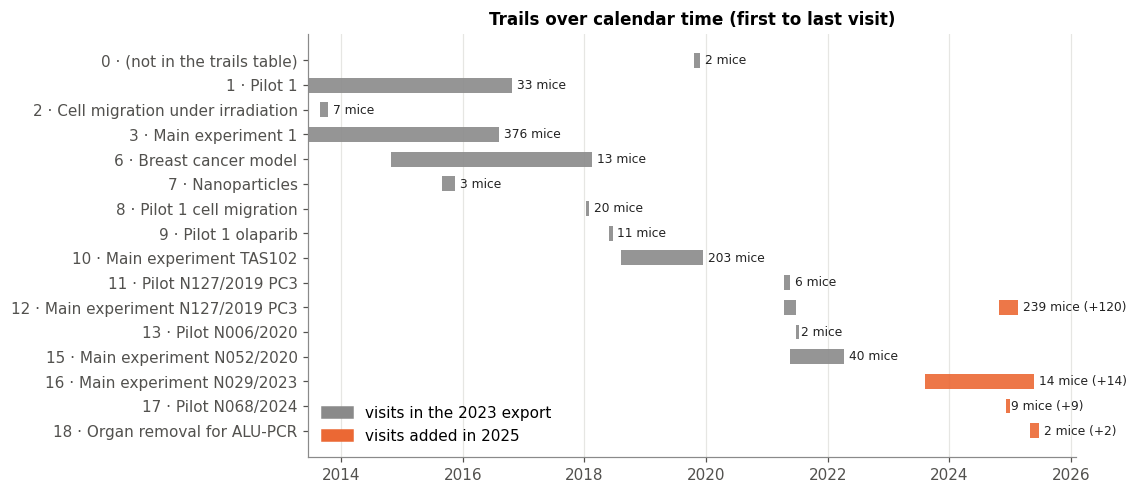

In [18]:
old_visit_ids = set(old["visits"]["visit_id"])
N.visits["in_old"] = N.visits["visit_id"].isin(old_visit_ids)
old_mouse_ids = set(old["mice"]["mouse_id"])
N.mice["in_old"] = N.mice["id"].isin(old_mouse_ids)
growth = pd.DataFrame({
    "mice old": O.mice.groupby("trail").size(), "mice new": N.mice.groupby("trail").size(),
    "visits old": O.visits.groupby("trail").size(), "visits new": N.visits.groupby("trail").size(),
}).fillna(0).astype(int)
growth["mice added"] = growth["mice new"] - growth["mice old"]
growth["visits added"] = growth["visits new"] - growth["visits old"]
growth["new trail"] = ~growth.index.isin(O.vr.index) & growth.index.isin(N.vr.index)
growth.index = growth.index.astype(int)
growth.index.name = "trail"
show(growth[(growth["mice added"] > 0) | (growth["visits added"] > 0)])

known = N.visits.dropna(subset=["date", "trail"])
spans = known.groupby(["trail", "in_old"])["date"].agg(["min", "max"]).unstack("in_old")
order = sorted(known["trail"].unique().astype(int), reverse=True)
fig, ax = plt.subplots(figsize=(9, 5))
for y, t in enumerate(order):
    for in_old, color in [(True, MUTED), (False, NEW_COLOR)]:
        if (("min", in_old) in spans.columns) and pd.notna(spans.loc[t, ("min", in_old)]):
            start, end = mdates.date2num(spans.loc[t, ("min", in_old)]), mdates.date2num(spans.loc[t, ("max", in_old)])
            ax.barh(y, max(end - start, 20), left=start, height=0.6, color=color, alpha=0.9)
    ax.text(mdates.date2num(known.loc[known["trail"] == t, "date"].max()) + 30, y,
            f"{growth.loc[t, 'mice new']} mice" + (f" (+{growth.loc[t, 'mice added']})" if growth.loc[t, "mice added"] else ""),
            va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(order)), [f"{t} · {N.trail_name(t)}" for t in order])
ax.xaxis_date()
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MUTED, label="visits in the 2023 export"),
                   plt.Rectangle((0, 0), 1, 1, color=NEW_COLOR, label="visits added in 2025")], loc="lower left")
ax.set_title("Trails over calendar time (first to last visit)")
plt.show()

## B3. Protocols per trail
Radiotherapy protocols (from the fractions in `radiotherapy`) and chemotherapy drugs and protocols (from
`chemotherapy`), with the number of mice. The schedule is fractions x dose per fraction of the protocol (the
protocols also differ in beam energy, 200 vs 225 kV). The last columns show how much of each trail uses the same RT
schedule and ChT drugs as trail 3.

In [19]:
rt_concepts = N.tables["rt_protocols"].set_index("rt_protocol_id")
rt = N.radio.merge(rt_concepts[["dose_per_fraction_gy", "fractions"]], left_on="rt_protocol_id", right_index=True, how="left")
rt["schedule"] = rt["fractions"].astype(str) + " x " + rt["dose_per_fraction_gy"].astype(str) + " Gy"
rt_per_mouse = rt.groupby(["trail", "id"]).agg(concept=("concept", "first"), schedule=("schedule", "first"),
                                                fractions=("fraction_id", "size"), dose=("delivered_dose_gy", "sum"))
cht_per_mouse = N.chemo.groupby(["trail", "id"]).agg(drug=("drug", "first"), concept=("concept", "first"),
                                                      administrations=("administration_id", "size"),
                                                      dose=("delivered_dose_mg_per_kg", "median"), route=("route", "first"))
rt3 = set(rt_per_mouse.loc[TRAIL, "schedule"])
cht3 = set(cht_per_mouse.loc[TRAIL, "drug"])
protocols = pd.DataFrame({
    "RT protocols (mice)": rt_per_mouse.groupby("trail")["concept"].agg(join_counts),
    "RT schedules (mice)": rt_per_mouse.groupby("trail")["schedule"].agg(join_counts),
    "RT fractions per mouse": rt_per_mouse.groupby("trail")["fractions"].agg(median_iqr),
    "RT total dose (Gy)": rt_per_mouse.groupby("trail")["dose"].agg(median_iqr),
    "ChT drugs (mice)": cht_per_mouse.groupby("trail")["drug"].agg(join_counts),
    "ChT protocols (mice)": cht_per_mouse.groupby("trail")["concept"].agg(join_counts),
    "ChT admin. per mouse": cht_per_mouse.groupby("trail")["administrations"].agg(median_iqr),
    "ChT routes": cht_per_mouse.groupby("trail")["route"].agg(join_unique),
    "% RT mice with trail-3 schedule": rt_per_mouse.groupby("trail")["schedule"].agg(lambda s: round(100 * s.isin(rt3).mean())),
    "% ChT mice with trail-3 drug": cht_per_mouse.groupby("trail")["drug"].agg(lambda s: round(100 * s.isin(cht3).mean())),
})
protocols.index = protocols.index.astype(int)
protocols.index.name = "trail"
show(protocols[["RT protocols (mice)", "RT schedules (mice)", "RT fractions per mouse", "RT total dose (Gy)",
                "% RT mice with trail-3 schedule"]].fillna(""), wide=["RT protocols (mice)", "RT schedules (mice)"])
show(protocols[["ChT drugs (mice)", "ChT protocols (mice)", "ChT admin. per mouse", "ChT routes",
                "% ChT mice with trail-3 drug"]].dropna(subset=["ChT drugs (mice)"]), wide=["ChT protocols (mice)"])

,RT protocols (mice),RT schedules (mice),RT fractions per mouse,RT total dose (Gy),% RT mice with trail-3 schedule
trail,,,,,
0,d1-5 2.0 Gy 1,5 x 2 Gy 1,3 [3–3],9 [9–9],0.000
1,d1-5 10.0 Gy 8,5 x 10 Gy 8,5 [5–5],50 [48–50],100.000
2,"d1 10.0 Gy 6, d1 15.0 Gy 1","1 x 10 Gy 6, 1 x 15 Gy 1",1 [1–1],10 [10–10],0.000
3,d1-5 10.0 Gy 134,5 x 10 Gy 134,5 [5–5],50 [50–50],100.000
4,"d1 6 Gy - femora 3, d1 6 Gy - mammary gland 3","2 x 6 Gy 3, 1 x 6 Gy 3",2 [1–2],9 [6–12],0.000
6,"Mammary02 d1 10.0 Gy 11, Mammary01 d1 3.0 Gy 1","1 x 10 Gy 11, 1 x 3 Gy 1",1 [1–1],10 [10–10],0.000
7,d1-5 10.0 Gy 3,5 x 10 Gy 3,5 [5–5],50 [50–50],100.000
8,"d1-4 10.0 Gy 1, d1 10.0 Gy 1, d1-3 10.0 Gy 1, d1-5 10.0 Gy 1, d1-2 10.0 Gy 1","4 x 10 Gy 1, 1 x 10 Gy 1, 3 x 10 Gy 1, 5 x 10 Gy 1, 2 x 10 Gy 1",3 [2–4],30 [20–40],20.000
9,d1 2.0 Gy 8,1 x 2 Gy 8,1 [1–1],2 [2–2],0.000


,ChT drugs (mice),ChT protocols (mice),ChT admin. per mouse,ChT routes,% ChT mice with trail-3 drug
trail,,,,,
1,"Cisplatin 19, Etoposide 6, Docetaxel 3","BC standard (old) 9, Doctaxel 20 mg/kg d1-8-15 3, Cisplatin 6mg/kg d1 2, Cisplatin dose 1/3 2, Cisplatin dose 2/3 2, Etoposide dose 3/3 2, Etoposide dose 1/3 2, Etoposide dose 2/3 2, Cisplatin + pause + etoposide 2, Cisplatin reduced + pause + etoposide 2",3 [3–4],i.p.,79.000
3,"Cisplatin 76, Docetaxel 40","Cisplatin 6mg/kg d1 76, Doctaxel 20 mg/kg d1-8-15 40",1 [1–3],i.p.,100.000
9,Olaparib 6,Olaparib 2 h before RT 6,1 [1–1],oral gavage,0.000
10,"TAS102 70, Capecitabine 53","TAS102 d1-10 52, Capecitabine d1-10 27, Capecitabine d1-5 26, TAS102 d1-5 18",10 [5–10],"oral gavage, unknown",0.000
11,Docetaxel 2,"Docetaxel d1,8 4 mg/kg 1, Docetaxel D1 8mg/kg 1",2 [1–2],i.p.,100.000
12,Docetaxel 76,"Docetaxel d1,8 4 mg/kg 76",2 [2–2],i.p.,100.000
15,Docetaxel 1,"Docetaxel d1,8 4 mg/kg 1",2 [2–2],i.p.,100.000
16,Ruthenium glutamine 10,Ruthenium glutamine d1 10,1 [1–1],i.p.,0.000


In [20]:
show(rt_concepts.loc[sorted(rt["rt_protocol_id"].unique()), ["name", "dose_per_fraction_gy", "total_dose_gy", "fractions",
                                                             "fractions_per_day", "fractions_per_week", "beam", "remark"]]
     .rename(columns={"dose_per_fraction_gy": "Gy per fraction", "total_dose_gy": "total Gy",
                      "fractions_per_day": "per day", "fractions_per_week": "per week"}))
drug_names = lookup(N.tables, "chemo_drugs", "drug_id", "name")
cp = N.tables["chemo_protocols"].set_index("chemo_protocol_id").loc[sorted(N.chemo["chemo_protocol_id"].unique())]
show(pd.DataFrame({"protocol": cp["name"], "drug 1": cp["drug_id_1"].map(drug_names), "dose 1 (mg/kg)": cp["dose_mg_per_kg_1"],
                   "days 1": cp["days_1"], "drug 2": cp["drug_id_2"].map(drug_names), "dose 2 (mg/kg)": cp["dose_mg_per_kg_2"],
                   "days 2": cp["days_2"], "remark": cp["remark"]}).fillna(""), wide=["remark"])

,name,Gy per fraction,total Gy,fractions,per day,per week,beam,remark
rt_protocol_id,,,,,,,,
1,d1-5 10.0 Gy,10,50,5,1,5,200 kV,Standard 5 x 10 Gy
2,d1 10.0 Gy,10,10,1,1,1,200 kV,Standard 1 x 10 Gy
3,d1 15.0 Gy,15,15,1,1,1,200 kV,Collaboration cell migration
4,d1 6 Gy - mammary gland,6,6,1,1,1,200 kV,Collaboration breast irradiation
5,d1 6 Gy - femora,6,12,2,2,2,200 kV,Collaboration breast irradiation
6,Mammary01 d1 3.0 Gy,3,3,1,1,1,200 kV,Collaboration breast cancer
7,Mammary02 d1 10.0 Gy,10,10,1,1,1,200 kV,Collaboration breast cancer
8,d1-4 10.0 Gy,10,40,4,1,4,200 kV,Standard 4 x 10 Gy
9,d1-3 10.0 Gy,10,30,3,1,3,200 kV,Standard 3 x 10 Gy


,protocol,drug 1,dose 1 (mg/kg),days 1,drug 2,dose 2 (mg/kg),days 2,remark
chemo_protocol_id,,,,,,,,
1,BC standard (old),Cisplatin,6,1,Etoposide,12.000,3,
2,Doctaxel 20 mg/kg d1-8-15,Docetaxel,20,3,,,,
3,Cisplatin dose 1/3,Cisplatin,2,1,,,,
4,Cisplatin dose 2/3,Cisplatin,4,1,,,,
5,Cisplatin 6mg/kg d1,Cisplatin,6,1,,0.000,,
6,Etoposide dose 1/3,Etoposide,4,3,,,,
7,Etoposide dose 2/3,Etoposide,8,3,,,,
8,Etoposide dose 3/3,Etoposide,12,3,,,,
9,Cisplatin + pause + etoposide,Cisplatin,6,1,Etoposide,12.000,3,"Cisplatin d1, etoposide d3-5"


## B4. Roles 12–14 (new in 2025)

In [21]:
special_roles = [r for r in (12, 13, 14) if r in set(N.mice["role"])]
special = N.mice[N.mice["role"].isin(special_roles)]
show(pd.DataFrame({"role": special_roles, "meaning": [N.role_name[r] for r in special_roles]}))
show(pd.crosstab(special["trail"].astype(int), special["role_abbr"].rename("role"), margins=True, margins_name="Total"))
MOUSE_TABLES = ["visits", "radiotherapy", "chemotherapy", "surgeries", "anaesthesia", "tumours", "tissue_samples",
                "blood_samples", "bone_marrow_samples", "cryo_samples", "paraffin_samples", "pcr"]
measured = pd.DataFrame({t: special.groupby("role_abbr")["id"].agg(lambda ids: int(new[t]["mouse_id"].isin(ids).sum()))
                         for t in MOUSE_TABLES})
measured.insert(0, "mice", special.groupby("role_abbr").size())
measured.columns = [c.replace("_samples", "").replace("_", " ") for c in measured.columns]
say("Rows per table for the mice of these roles:")
show(measured)
special_visits = N.visits[N.visits["id"].isin(special["id"])]
show(special_visits.groupby("id").agg(trail=("trail", "first"), role=("role", "first"), visits=("weight", "size"),
                                      first=("date", "min"), last=("date", "max"), weight=("weight", "median"))
     .astype({"trail": int, "role": int}).assign(first=lambda x: x["first"].dt.date, last=lambda x: x["last"].dt.date))

role,meaning
12,OrganRem: organ removal
13,Macro: injection of macrophages
14,Nano: injection of nanoparticles


role,Macro,Nano,OrganRem,Total
trail,,,,
16,3,1,0,4
18,0,0,2,2
Total,3,1,2,6


Rows per table for the mice of these roles:

,mice,visits,radiotherapy,chemotherapy,surgeries,anaesthesia,tumours,tissue,blood,bone marrow,cryo,paraffin,pcr
role_abbr,,,,,,,,,,,,,
Macro,3,97,0,0,0,0,3,0,0,0,0,0,0
Nano,1,32,0,0,0,0,1,0,0,0,0,0,0
OrganRem,2,116,0,0,0,0,0,16,2,2,6,8,0


,trail,role,visits,first,last,weight
id,,,,,,
985,16,13,32,2025-04-29,2025-05-24,18.100
986,16,13,31,2025-04-29,2025-05-24,18.900
987,16,14,32,2025-04-29,2025-05-25,17.900
988,16,13,34,2025-04-29,2025-05-25,20.000
989,18,12,58,2025-04-29,2025-06-24,20.050
990,18,12,58,2025-04-29,2025-06-24,23.150


In [22]:
n_new_trails = int(growth["new trail"].sum())
t12 = growth.loc[12]
comparable = protocols[(protocols["% RT mice with trail-3 schedule"].fillna(0) >= 50)].index.tolist()
cht_shared = protocols[(protocols["% ChT mice with trail-3 drug"].fillna(0) >= 50)].index.tolist()
big_trails = [t for t in trails_new.index[trails_new["mice"] > 100] if t != TRAIL]
say(f"""**What this tells us (Part B).**
- The new export has {len(N.vr)} trails ({n_new_trails} new: {", ".join(str(t) for t in growth.index[growth["new trail"]])}).
  Most of the growth is trail 12, which went from {t12['mice old']} to {t12['mice new']} mice and from
  {t12['visits old']:,} to {t12['visits new']:,} visits; the new trails are small
  ({", ".join(f"trail {t}: {growth.loc[t, 'mice new']} mice" for t in growth.index[growth["new trail"]])}).
- Trail 3 remains the largest trail ({trails_new.loc[TRAIL, 'mice']} mice); the only other trails with more than 100 mice
  are {", ".join(f"{t} ({trails_new.loc[t, 'mice']})" for t in big_trails)}.
- Trails in which at least half of the irradiated mice got trail 3's RT schedule ({", ".join(sorted(rt3))}):
  {", ".join(map(str, comparable))}. Trails in which at least half of the ChT mice got a trail-3 drug
  ({", ".join(sorted(cht3))}): {", ".join(map(str, cht_shared))}. The other trails ran different protocols
  (e.g. fractionated 2–3 Gy schedules, TAS102/capecitabine) and are different experiments.
- Roles 12–14 cover {len(special)} mice in trail(s) {join_unique(special['trail'].astype(int))} with
  {len(special_visits)} visits ({100 * len(special_visits) / len(N.visits):.1f}% of all visits); their weights were recorded
  but they got no RT/ChT, and the organ-removal mice have necropsy samples only.
""")

**What this tells us (Part B).**
- The new export has 18 trails (3 new: 16, 17, 18).
  Most of the growth is trail 12, which went from 119 to 239 mice and from
  4,705 to 10,062 visits; the new trails are small
  (trail 16: 14 mice, trail 17: 9 mice, trail 18: 2 mice).
- Trail 3 remains the largest trail (376 mice); the only other trails with more than 100 mice
  are 10 (203), 12 (239).
- Trails in which at least half of the irradiated mice got trail 3's RT schedule (5 x 10 Gy):
  1, 3, 7, 11, 12. Trails in which at least half of the ChT mice got a trail-3 drug
  (Cisplatin, Docetaxel): 1, 3, 11, 12, 15. The other trails ran different protocols
  (e.g. fractionated 2–3 Gy schedules, TAS102/capecitabine) and are different experiments.
- Roles 12–14 cover 6 mice in trail(s) 16, 18 with
  245 visits (0.9% of all visits); their weights were recorded
  but they got no RT/ChT, and the organ-removal mice have necropsy samples only.


# Part C: usability per trail for weight forecasting

## C1. Cohort flow per trail
Replays `michael.load_dataset` step by step (as v1 C1), for all trails at once, on the original-schema export the
loader reads. Each column is the number of mice left after that filter. "lost to trail start" counts mice that
would have had enough weights if the records before the trail start or birth were not dropped. The final column is
checked against `michael.load_dataset`.

In [23]:
def cohort_flow(path, roles, untreated=michael.UNTREATED):
    """Mice per trail after each filter of michael.load_dataset, and the loader's result for the same settings."""
    tables = pd.read_pickle(path)  # original schema, as read by the loader
    cfg = config(sorted(tables["Versuchsreihen"]["IdVersuchsreihe"]), roles)
    columns = preprocessing.MOUSE_COLUMNS | {"Geburtsdatum": "birth date", "Sterbedatum": "death date"}
    m_all = tables["Versuchstiere"][list(columns)].rename(columns=columns)
    starts = tables["Versuchsreihen"][["IdVersuchsreihe", "VersuchStart"]].rename(
        columns={"IdVersuchsreihe": "trail", "VersuchStart": "trail start"})
    m = m_all.merge(starts, on="trail", how="left")
    for column in ("birth date", "death date", "trail start"):
        m[column] = pd.to_datetime(m[column], errors="coerce")
    m_dead = m[m["trail"].isin(starts["trail"]) & m["role"].isin(roles) & m["death date"].notna()]
    events = michael._build_events(tables, m_dead).merge(m_dead[["id", "trail", "role", "birth date", "trail start"]], on="id")
    events["days_since"] = (events["date"] - events["trail start"]).dt.days
    dated = events[(events["date"] >= events["birth date"]) & (events["days_since"] >= 0)]
    dated = dated.assign(weight=dated["weight"].round(2)).sort_values(["id", "days_since"], kind="stable")
    per = dated.groupby("id").agg(events=("event", lambda e: tuple(e.unique())), n=("weight", "count"),
                                  min_weight=("weight", "min"), max_weight=("weight", "max")).reindex(m["id"])
    per.index = m.index
    n_undated = events.groupby("id")["weight"].count().reindex(m["id"]).fillna(0).to_numpy()
    steps = {
        "in trails table": m["trail"].isin(starts["trail"]),
        f"role {'1–3' if list(roles) == COHORT_ROLES else 'any'}": m["role"].isin(roles),
        "death date known": m["death date"].notna(),
        "treated": per["events"].map(lambda e: isinstance(e, tuple) and e not in untreated),
        f"≥ {cfg.min_length} weights": per["n"] >= cfg.min_length,
        "weights > 0 g": per["min_weight"] > 0,
        f"weights ≤ {cfg.max_weight:g} g": per["max_weight"] <= cfg.max_weight,
    }
    flow = pd.DataFrame({"all mice": m.groupby("trail").size()})
    mask = pd.Series(True, index=m.index)
    for label, step in steps.items():
        mask &= step.fillna(False).astype(bool)
        flow[label] = mask.groupby(m["trail"]).sum()
    lost_start = (per["n"].fillna(0) < cfg.min_length) & (n_undated >= cfg.min_length) & m.index.isin(m_dead.index)
    flow["lost to trail start"] = lost_start.groupby(m["trail"]).sum()
    flow.index = flow.index.astype(int)
    flow.index.name = "trail"
    with mock.patch.object(michael, "UNTREATED", untreated):
        loaded = michael.load_dataset(path, cfg)
    kept = set(m.loc[mask, "id"])
    assert kept == set(loaded["item_id"]), "replay does not match michael.load_dataset"
    return flow, loaded


flow13, D13 = cohort_flow(NEW_PATH, COHORT_ROLES)
say(f"**Roles RT/RChT/ChT** — kept: {D13['item_id'].nunique()} mice, {len(D13):,} rows "
    f"(old export: {df_all_old['item_id'].nunique()} mice, {len(df_all_old):,} rows). "
    "*treated*: RT, ChT or surgery recorded.")
show(flow13)

**Roles RT/RChT/ChT** — kept: 519 mice, 16,376 rows (old export: 434 mice, 12,397 rows). *treated*: RT, ChT or surgery recorded.

,all mice,in trails table,role 1–3,death date known,treated,≥ 5 weights,weights > 0 g,weights ≤ 100 g,lost to trail start
trail,,,,,,,,,
0,2,0,0,0,0,0,0,0,0
1,33,33,31,29,29,29,26,26,0
2,7,7,7,0,0,0,0,0,0
3,376,376,188,188,188,188,187,186,0
4,6,6,6,0,0,0,0,0,0
5,2,2,0,0,0,0,0,0,0
6,13,13,13,13,13,0,0,0,0
7,3,3,3,3,3,3,3,3,0
8,20,20,5,5,5,5,5,5,0


Mice kept per trail and role:

In [24]:
def kept_by_role(d):
    first = d.drop_duplicates("item_id")
    return pd.crosstab(first["trail"].astype(int), first["role"].map(N.role_abbr).rename("role"), margins=True, margins_name="Total")


show(kept_by_role(D13))

role,ChT,RChT,RT,Total
trail,,,,
1,18,7,1,26
3,53,60,73,186
7,0,0,3,3
8,0,0,5,5
10,44,71,38,153
11,1,1,4,6
12,36,39,39,114
15,0,0,17,17
16,9,0,0,9


## C2. Widening the role filter
The same flow with all roles. Controls and other untreated mice are then removed by the *treated* filter
(Michael's loader drops mice without RT/ChT/OP), so a second run switches that filter off
(`michael.UNTREATED` patched to an empty list, inside this notebook only) to see what the untreated mice
could add as context.

In [25]:
all_roles = sorted(set(N.mice["role"]))
flow_all, D_allroles = cohort_flow(NEW_PATH, all_roles)
flow_ctx, D_ctx = cohort_flow(NEW_PATH, all_roles, untreated=[])
say(f"All roles: {D_allroles['item_id'].nunique()} mice kept with the treatment filter, "
    f"{D_ctx['item_id'].nunique()} mice and {len(D_ctx):,} rows without it.")
show(flow_all)


def series_summary(d):
    pm = d.sort_values(["item_id", "timestamp"]).groupby("item_id").agg(
        trail=("trail", "first"), role=("role", "first"), n=("target", "size"), baseline=("target", "first"),
        treated=("intervention", "max"), first=("timestamp", "min"), last=("timestamp", "max"))
    pm["median_gap"] = d.sort_values(["item_id", "timestamp"]).groupby("item_id")["timestamp"].apply(
        lambda s: s.diff().dt.days.median())
    return pm


pm_ctx = series_summary(D_ctx)
by_role = pm_ctx.groupby("role").agg(
    mice=("n", "size"), rows=("n", "sum"), treated=("treated", "sum"),
    length=("n", median_iqr), median_gap_days=("median_gap", median_iqr),
    baseline_g=("baseline", lambda x: median_iqr(x, 1)), trails=("trail", lambda t: join_counts(t.astype(int))))
by_role.index = [f"{r} {N.role_abbr.get(r, '?')}" for r in by_role.index]
by_role.index.name = "role"
show(by_role, wide=["trails"])

All roles: 740 mice kept with the treatment filter, 888 mice and 26,974 rows without it.

,all mice,in trails table,role any,death date known,treated,≥ 5 weights,weights > 0 g,weights ≤ 100 g,lost to trail start
trail,,,,,,,,,
0,2,0,0,0,0,0,0,0,0
1,33,33,33,31,31,31,28,28,0
2,7,7,7,0,0,0,0,0,0
3,376,376,376,376,310,290,289,288,0
4,6,6,6,0,0,0,0,0,0
5,2,2,2,2,0,0,0,0,0
6,13,13,13,13,13,0,0,0,0
7,3,3,3,3,3,3,3,3,0
8,20,20,20,20,20,20,20,20,0


,mice,rows,treated,length,median_gap_days,baseline_g,trails
role,,,,,,,
0 –,5,150,0,30 [30–30],1 [1–1],31.2 [30.0–32.3],10 5
1 RT,180,5761,180,31 [16–41],1 [1–2],23.5 [21.4–26.3],"3 73, 12 39, 10 38, 15 17, 8 5, 11 4, 7 3, 1 1"
2 RChT,178,5812,178,34 [16–43],1 [1–2],23.6 [21.1–27.2],"10 71, 3 60, 12 39, 1 7, 11 1"
3 ChT,163,4838,161,27 [16–40],1 [1–3],24.2 [21.1–27.1],"3 53, 10 46, 12 36, 1 18, 16 9, 11 1"
4 C-start,86,1914,0,18 [8–32],1 [1–6],22.8 [20.9–25.4],"3 40, 12 40, 8 6"
5 C-end,160,3908,2,22 [14–36],1 [1–3],23.6 [21.5–27.1],"3 73, 12 39, 10 29, 15 13, 8 6"
7 Obs,6,208,0,22 [22–45],2 [1–6],25.8 [24.4–26.6],"8 3, 1 2, 3 1"
8 NoTumour,42,1869,0,46 [13–74],1 [1–7],25.5 [22.7–28.7],"3 33, 15 7, 10 1, 12 1"
9 Surgery,62,2294,62,37 [31–42],1 [1–1],21.2 [20.3–23.2],"12 44, 3 18"


## C3. Series characteristics per trail
For the roles RT/RChT/ChT through `michael.load_dataset` (`D13`), all trails. Gaps are days between
consecutive rows of a mouse; loss is the lowest weight relative to the first one.

In [26]:
def per_mouse_table(d):
    s = d.sort_values(["item_id", "timestamp"])
    pm = s.groupby("item_id").agg(trail=("trail", "first"), role=("role", "first"), n=("target", "size"),
                                  first=("timestamp", "min"), last=("timestamp", "max"), baseline=("target", "first"),
                                  min_weight=("target", "min"), intervention_rows=("intervention", "sum"))
    pm["nadir_pct"] = 100 * pm["min_weight"] / pm["baseline"]
    first_treat = s[s["intervention"] > 0].groupby("item_id")["timestamp"].min()
    pm["first_treatment"] = first_treat
    pm["measurements_before_treatment"] = s.assign(before=s["timestamp"] < s["item_id"].map(first_treat)).groupby("item_id")["before"].sum()
    return pm


def gaps_table(d):
    s = d.sort_values(["item_id", "timestamp"]).copy()
    s["gap"] = s.groupby("item_id")["timestamp"].diff().dt.days
    s["delta"] = s.groupby("item_id")["target"].diff()
    return s


pm13 = per_mouse_table(D13)
g13 = gaps_table(D13)
trail_counts = pm13["trail"].value_counts()
kept_trails = sorted(trail_counts[trail_counts >= MIN_MICE].index.astype(int))
characteristics = pd.DataFrame({
    "mice": pm13.groupby("trail").size(),
    "rows": D13.groupby("trail").size(),
    "series length": pm13.groupby("trail")["n"].agg(median_iqr),
    "median gap (days)": g13.groupby("trail")["gap"].median(),
    "% gaps 1 day": g13.groupby("trail")["gap"].agg(lambda x: round(100 * (x == 1).mean())),
    "% gaps 7 days": g13.groupby("trail")["gap"].agg(lambda x: round(100 * (x == 7).mean())),
    "% gaps > 7 days": g13.groupby("trail")["gap"].agg(lambda x: round(100 * (x > 7).mean())),
    "% rows on Mondays": D13.groupby("trail")["timestamp"].agg(lambda x: round(100 * (x.dt.dayofweek == 0).mean())),
    "time of day (h)": D13.groupby("trail")["time_of_day"].agg(lambda x: median_iqr(x, 1)),
    "% rows without time": D13.groupby("trail")["time_of_day"].agg(lambda x: round(100 * x.isna().mean())),
    "baseline weight (g)": pm13.groupby("trail")["baseline"].agg(lambda x: median_iqr(x, 1)),
    "step change SD (g)": g13.groupby("trail")["delta"].std().round(2),
    "% mice ≥ 10% loss": pm13.groupby("trail")["nadir_pct"].agg(lambda x: round(100 * (x <= 90).mean())),
    "% mice ≥ 20% loss": pm13.groupby("trail")["nadir_pct"].agg(lambda x: round(100 * (x <= 80).mean())),
    "% rows with treatment": D13.groupby("trail")["intervention"].agg(lambda x: round(100 * x.mean())),
    "weights before 1st treatment": pm13.groupby("trail")["measurements_before_treatment"].agg(median_iqr),
})
characteristics.index = characteristics.index.astype(int)
characteristics.index.name = "trail"
half_cols = len(characteristics.columns) // 2
show(characteristics.iloc[:, :half_cols])
show(characteristics.iloc[:, half_cols:])

,mice,rows,series length,median gap (days),% gaps 1 day,% gaps 7 days,% gaps > 7 days,% rows on Mondays
trail,,,,,,,,
1,26,1047,28 [8–76],7.000,15,56,4,67
3,186,3049,15 [11–16],2.000,44,24,1,45
7,3,39,13 [13–13],4.500,31,0,23,15
8,5,110,22 [22–22],1.000,95,0,0,18
10,153,5808,37 [27–48],1.000,93,0,0,16
11,6,181,29 [29–33],1.000,95,0,0,14
12,114,4900,40 [40–45],1.000,98,0,0,14
15,17,900,43 [17–81],1.000,98,0,0,14
16,9,342,47 [5–62],1.000,97,0,0,14


,time of day (h),% rows without time,baseline weight (g),step change SD (g),% mice ≥ 10% loss,% mice ≥ 20% loss,% rows with treatment,weights before 1st treatment
trail,,,,,,,,
1,10.9 [9.6–13.3],0,25.1 [24.2–27.1],0.900,54,35,8,0 [0–5]
3,12.2 [10.1–16.1],0,25.6 [22.8–27.8],1.020,57,22,26,7 [3–8]
7,9.6 [7.5–15.5],0,21.3 [21.2–21.8],0.700,0,0,38,3 [3–3]
8,9.5 [8.4–10.4],0,24.1 [23.7–25.4],0.470,40,0,14,14 [14–14]
10,11.7 [9.8–13.2],0,24.4 [21.8–28.9],0.430,21,3,20,14 [12–14]
11,8.8 [8.2–10.4],0,21.1 [20.2–23.1],0.620,50,17,9,22 [18–27]
12,10.0 [8.5–11.6],0,20.8 [19.3–21.7],0.520,13,3,10,32 [31–36]
15,6.9 [6.8–7.0],0,26.8 [25.1–29.9],0.730,41,12,16,0 [0–1]
16,9.6 [8.1–11.2],0,23.0 [20.9–24.3],0.360,0,0,3,46 [4–61]


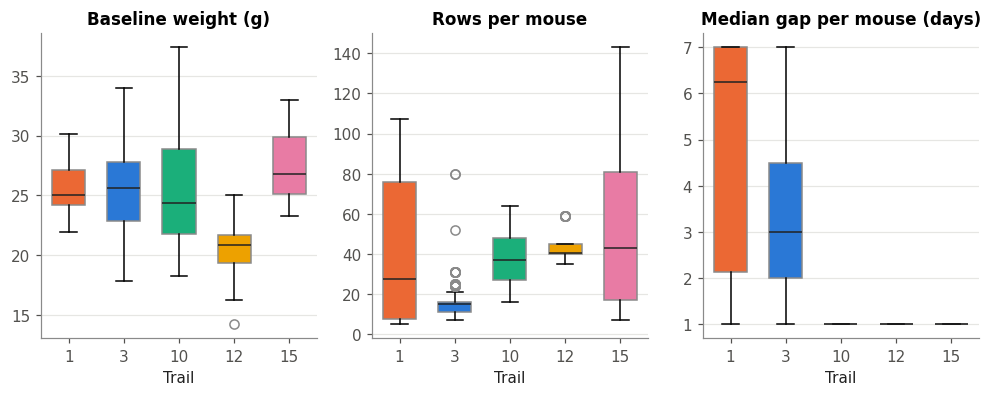

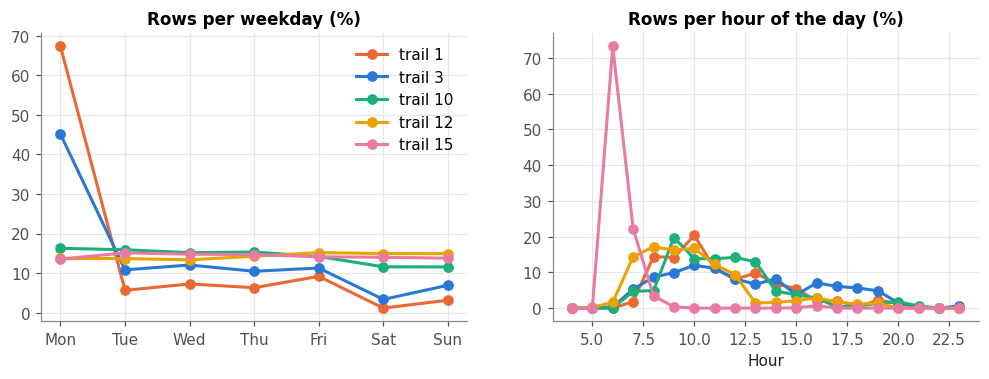

In [27]:
colors = trail_colors(kept_trails)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (data, label) in zip(axes, [(pm13["baseline"], "Baseline weight (g)"), (pm13["n"], "Rows per mouse"),
                                     (g13.groupby("item_id")["gap"].median(), "Median gap per mouse (days)")]):
    values = [data[pm13["trail"] == t].dropna() for t in kept_trails]
    box = ax.boxplot(values, patch_artist=True, widths=0.6, medianprops={"color": INK}, flierprops={"markeredgecolor": MUTED})
    for patch, t in zip(box["boxes"], kept_trails):
        patch.set_facecolor(colors[t])
        patch.set_edgecolor(MUTED)
    ax.set_xticks(range(1, len(kept_trails) + 1), kept_trails)
    ax.set_xlabel("Trail")
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
weekday_share = pd.crosstab(D13["trail"], D13["timestamp"].dt.dayofweek, normalize="index").mul(100).loc[kept_trails]
hour_share = pd.crosstab(D13["trail"], np.floor(D13["time_of_day"]), normalize="index").mul(100).loc[kept_trails]
for t in kept_trails:
    axes[0].plot(weekday_share.columns, weekday_share.loc[t], marker="o", color=colors[t], label=f"trail {t}")
    axes[1].plot(hour_share.columns, hour_share.loc[t], marker="o", color=colors[t], label=f"trail {t}")
axes[0].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].set_title("Rows per weekday (%)")
axes[1].set_title("Rows per hour of the day (%)")
axes[1].set_xlabel("Hour")
axes[0].legend()
plt.show()

## C4. Shift against trail 3
Population, era and protocol of the trails with at least `MIN_MICE` kept mice, and the weight course
aligned at the first treatment (median over mice in 3-day bins, as v1 C4).

,mice,strain,% male,cell lines,years,roles,RT protocols,ChT drugs,days 1st row → 1st treatment
trail,,,,,,,,,
1,26,"SCID 23, PFP/RAG2 3",81,"PC-3 RGB 3, OH-1 RGB 3, H69 RGB 2",2013–2013,"ChT 18, RChT 7, RT 1",d1-5 10.0 Gy 8,"Cisplatin 16, Etoposide 6, Docetaxel 3",0 [0–21]
3,186,"SCID 128, PFP/RAG2 58",66,"OH-1 RGB 81, LNCaP RGB 58, H69 RGB 47",2013–2016,"RT 73, RChT 60, ChT 53",d1-5 10.0 Gy 133,"Cisplatin 74, Docetaxel 40",28 [21–49]
10,153,PFP/RAG2 153,43,"SW48 55, HT29 49, HCT116 49",2018–2019,"RChT 71, ChT 44, RT 38","d1-10 3.0 Gy 64, d1-5 2.0 Gy 37, d1 2.0 Gy 4, d1 3.0 Gy 4","TAS102 67, Capecitabine 48",14 [14–16]
12,114,SCID 114,100,"PC-3DR RGB + luciferase 60, PC-3 RGB + luciferase 54",2021–2024,"RChT 39, RT 39, ChT 36","d1-5 10.0 Gy 225 kV 69, d1-5 10.0 Gy 9",Docetaxel 75,32 [31–36]
15,17,NMRI-Foxn1nu 17,0,NCH644OBC 17,2021–2022,RT 17,"d1-10 2.0 Gy 10, d1-6 6x2.0 Gy 7",,0 [0–1]


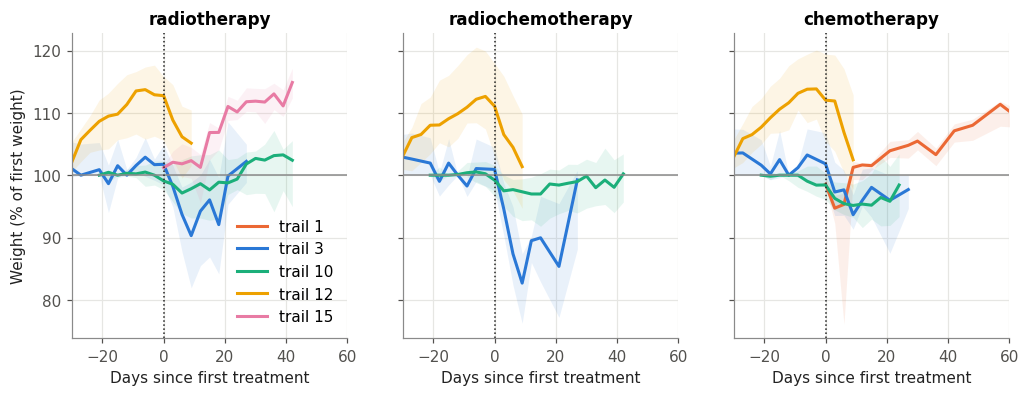

In [28]:
mice_k = N.mice.set_index("id").loc[pm13.index]
shift = pd.DataFrame({
    "mice": pm13.groupby("trail").size(),
    "strain": mice_k.groupby("trail")["strain"].agg(join_counts),
    "% male": mice_k.groupby("trail")["sex"].agg(lambda s: round(100 * (s == "male").mean())),
    "cell lines": mice_k.groupby("trail")["cell_line"].agg(join_counts),
    "years": pm13.groupby("trail")["first"].agg(lambda x: f"{x.dt.year.min()}–{x.dt.year.max()}"),
    "roles": pm13.groupby("trail")["role"].agg(lambda r: join_counts(r.map(N.role_abbr))),
    "RT protocols": rt_per_mouse.reset_index().query("id in @pm13.index").groupby("trail")["concept"].agg(join_counts),
    "ChT drugs": cht_per_mouse.reset_index().query("id in @pm13.index").groupby("trail")["drug"].agg(join_counts),
    "days 1st row → 1st treatment": (pm13["first_treatment"] - pm13["first"]).dt.days.groupby(pm13["trail"]).agg(median_iqr),
}).loc[kept_trails].fillna("")
shift.index.name = "trail"
show(shift, wide=["cell lines", "RT protocols"])

traj = D13.join(pm13[["first_treatment", "baseline", "last"]], on="item_id")
traj["day_rel_treatment"] = (traj["timestamp"] - traj["first_treatment"]).dt.days
traj["rel_weight"] = 100 * traj["target"] / traj["baseline"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, role in zip(axes, COHORT_ROLES):
    for t in kept_trails:
        q = median_line(traj[(traj["trail"] == t) & (traj["role"] == role)], "day_rel_treatment", "rel_weight")
        if len(q):
            ax.fill_between(q.index, q["q1"], q["q3"], color=colors[t], alpha=0.1, linewidth=0)
            ax.plot(q.index, q["med"], color=colors[t], label=f"trail {t}")
    ax.axhline(100, color=MUTED, linewidth=1)
    ax.axvline(0, color=INK, linestyle=":", linewidth=1)
    ax.set_xlim(-30, 60)
    ax.set_title(N.role_name[role].split(":")[1].strip())
    ax.set_xlabel("Days since first treatment")
axes[0].set_ylabel("Weight (% of first weight)")
axes[0].legend(handles=[plt.Line2D([], [], color=colors[t], label=f"trail {t}") for t in kept_trails])
plt.show()

Time on study (tumour injection to death) per trail, RT/RChT/ChT mice of the kept series (v1's
Kaplan–Meier plot, by trail instead of role). As in v1, almost all deaths are planned, so the curves show
the follow-up design.

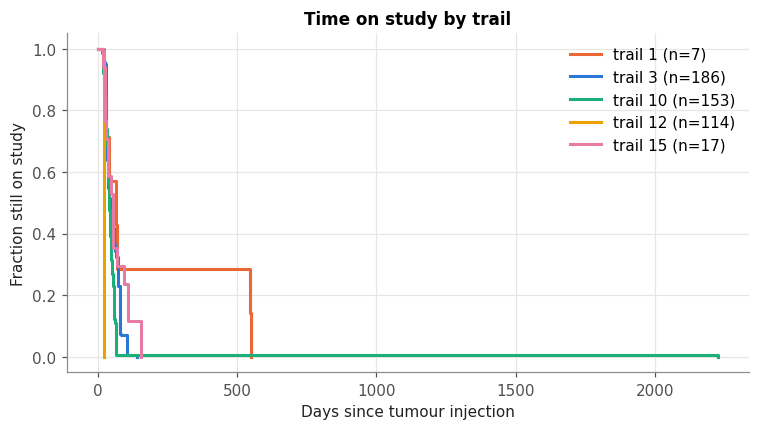

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
days_on_study = (mice_k["death"] - mice_k["injection"]).dt.days
for t in kept_trails:
    x = days_on_study[mice_k["trail"] == t].dropna()
    x = x[x >= 0]
    if len(x):
        sf = SurvfuncRight(x.to_numpy(float), np.ones(len(x)))
        ax.step(np.r_[0, sf.surv_times], np.r_[1, sf.surv_prob], where="post", color=colors[t], label=f"trail {t} (n={len(x)})")
ax.set_xlabel("Days since tumour injection")
ax.set_ylabel("Fraction still on study")
ax.set_title("Time on study by trail")
ax.legend()
plt.show()

## C5. Trail 12: old half vs new half
Trail-12 mice that are already in the 2023 export against those added since.

In [30]:
m12 = N.mice[N.mice["trail"] == 12].copy()
m12["half"] = np.where(m12["in_old"], "old (in 2023 export)", "new (added 2025)")
first_visit = N.visits.dropna(subset=["date"]).groupby("id")["date"].agg(["min", "max"])
m12 = m12.join(first_visit, on="id")
halves = m12.groupby("half").agg(
    mice=("id", "size"), first_visit=("min", "min"), last_visit=("max", "max"),
    cohorts=("cohort", join_counts), cell_lines=("cell_line", join_counts), strains=("strain", join_counts),
    roles=("role_abbr", join_counts), male=("sex", lambda s: int((s == "male").sum())),
)
half_of = m12.set_index("id")["half"]
rt12 = rt_per_mouse.loc[12].reset_index()
cht12 = cht_per_mouse.loc[12].reset_index()
halves["RT protocols"] = rt12.groupby(rt12["id"].map(half_of))["concept"].agg(join_counts)
halves["ChT drugs"] = cht12.groupby(cht12["id"].map(half_of))["drug"].agg(join_counts)
pm12 = pm13[pm13["trail"] == 12].assign(half=lambda x: x.index.map(half_of))
halves["kept series (RT/RChT/ChT)"] = pm12.groupby("half").size()
halves["series length"] = pm12.groupby("half")["n"].agg(median_iqr)
halves["baseline weight (g)"] = pm12.groupby("half")["baseline"].agg(lambda x: median_iqr(x, 1))
halves["lowest weight (% of first)"] = pm12.groupby("half")["nadir_pct"].agg(lambda x: median_iqr(x, 1))
g12 = g13[g13["trail"] == 12].assign(half=lambda x: x["item_id"].map(half_of))
halves["median gap (days)"] = g12.groupby("half")["gap"].median()
show(halves.assign(first_visit=lambda x: x["first_visit"].dt.date, last_visit=lambda x: x["last_visit"].dt.date)
     .astype(str).T.rename_axis("trail 12"))

half,new (added 2025),old (in 2023 export)
trail 12,,
mice,120,119
first_visit,2024-10-24,2021-04-15
last_visit,2025-02-16,2021-06-25
cohorts,PC-3DR RGB + luciferase main experiment 120,PC-3 RGB + luciferase main experiment 119
cell_lines,PC-3DR RGB + luciferase 120,PC-3 RGB + luciferase 119
strains,SCID 120,SCID 119
roles,"C-start 20, ChT 20, RChT 20, Surgery 20, RT 20, C-end 19, NoTumour 1","Surgery 24, C-start 20, C-end 20, RChT 20, RT 19, ChT 16"
male,120,119
RT protocols,d1-5 10.0 Gy 225 kV 40,"d1-5 10.0 Gy 225 kV 29, d1-5 10.0 Gy 10"


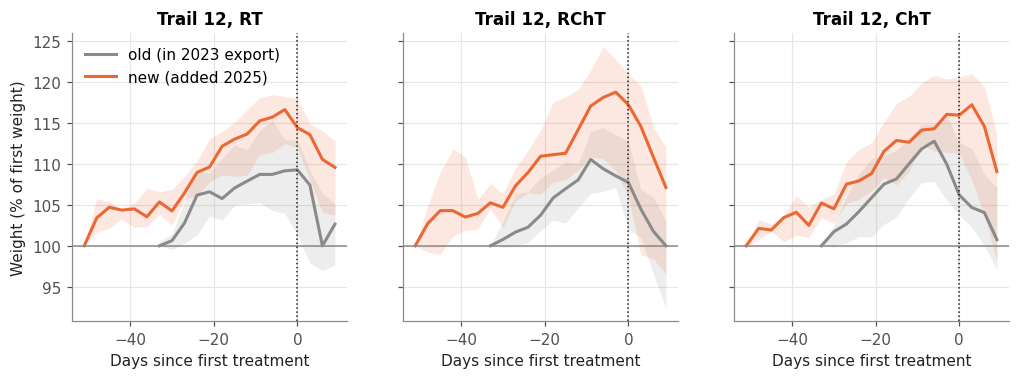

In [31]:
traj12 = traj[traj["trail"] == 12].assign(half=lambda x: x["item_id"].map(half_of))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, role in zip(axes, COHORT_ROLES):
    for half, color in [("old (in 2023 export)", MUTED), ("new (added 2025)", NEW_COLOR)]:
        q = median_line(traj12[(traj12["role"] == role) & (traj12["half"] == half)], "day_rel_treatment", "rel_weight", min_n=5)
        if len(q):
            ax.fill_between(q.index, q["q1"], q["q3"], color=color, alpha=0.15, linewidth=0)
            ax.plot(q.index, q["med"], color=color, label=half)
    ax.axhline(100, color=MUTED, linewidth=1)
    ax.axvline(0, color=INK, linestyle=":", linewidth=1)
    ax.set_title(f"Trail 12, {N.role_abbr[role]}")
    ax.set_xlabel("Days since first treatment")
axes[0].set_ylabel("Weight (% of first weight)")
axes[0].legend()
plt.show()

## C6. Naive last-value error per trail
The error of "next weight = last weight" on the rolling one-step-ahead origins (v1 C7), a yardstick for how
hard each trail is. *Overall* is the mean of the three role MAEs, as in the results tables. The rolling
machinery is run once on trail 3 and must match v1 (0.695 g); per trail the same numbers are computed
directly (the last-value forecast of origin *k* is weight *k − 1*).

In [32]:
last_value = {"Last value": lambda c, t: c.sort_values(["item_id", "timestamp"]).groupby("item_id", as_index=False)["target"]
              .last().rename(columns={"target": "prediction"})}
naive3 = rolling_metrics(rolling_predictions(df3_new, last_value, min_context=MIN_CONTEXT))
naive3_overall = float(naive3.xs("Overall", level="role")["MAE"].iloc[0])
print(f"Trail 3 via rolling_predictions: overall MAE {naive3_overall:.3f} g")
assert round(naive3_overall, 3) == 0.695


def naive_errors(d):
    """Absolute error of the last-value forecast for every rolling origin (step ≥ MIN_CONTEXT)."""
    s = d.sort_values(["item_id", "timestamp"]).copy()
    s["step"] = s.groupby("item_id").cumcount()
    s["ae"] = (s["target"] - s.groupby("item_id")["target"].shift()).abs()
    return s[s["step"] >= MIN_CONTEXT]


def naive_table(errors, by="trail"):
    per_role = errors.groupby([by, "role"])["ae"].mean().unstack("role")
    out = pd.DataFrame({"mice": errors.groupby(by)["item_id"].nunique(), "origins": errors.groupby(by).size()})
    for r in COHORT_ROLES:
        out[f"MAE {N.role_abbr[r]}"] = per_role.get(r)
    out["MAE overall (mean of roles)"] = per_role.reindex(columns=COHORT_ROLES).mean(axis=1, skipna=False)
    out["MAE all origins"] = errors.groupby(by)["ae"].mean()
    return out.round(3)


e13 = naive_errors(D13)
check3 = naive_table(e13[e13["trail"] == TRAIL]).loc[TRAIL, "MAE overall (mean of roles)"]
assert abs(check3 - naive3_overall) < 1e-3, (check3, naive3_overall)
naive_per_trail = naive_table(e13)
naive_per_trail.index = naive_per_trail.index.astype(int)
naive_per_trail.index.name = "trail"
show(naive_per_trail)

Trail 3 via rolling_predictions: overall MAE 0.695 g


,mice,origins,MAE RT,MAE RChT,MAE ChT,MAE overall (mean of roles),MAE all origins
trail,,,,,,,
1,26,995,0.996,0.536,0.561,0.697,0.564
3,186,2677,0.541,0.844,0.701,0.695,0.662
7,3,33,0.412,,,,0.412
8,5,100,0.363,,,,0.363
10,153,5502,0.147,0.172,0.175,0.165,0.166
11,6,169,0.450,0.484,0.500,0.478,0.466
12,114,4672,0.343,0.372,0.376,0.363,0.363
15,17,866,0.509,,,,0.509
16,9,324,,,0.276,,0.276


In [33]:
mae = naive_per_trail["MAE all origins"]
step_cols = list(flow13.columns[1:-1])
losses = pd.Series({b: int((flow13[a] - flow13[b]).sum()) for a, b in zip(["all mice"] + step_cols[:-1], step_cols)})
top_losses = losses.sort_values(ascending=False).head(3)
extra = pm_ctx.loc[~pm_ctx.index.isin(D13["item_id"])]
extra_controls = int(extra["role"].isin([4, 5]).sum())
bigger = [t for t in kept_trails if t != TRAIL]
same_strain = [t for t in bigger if set(mice_k.loc[mice_k["trail"] == t, "strain"].dropna()) & set(mice_k.loc[mice_k["trail"] == TRAIL, "strain"].dropna())]
same_cells = [t for t in bigger if set(mice_k.loc[mice_k["trail"] == t, "cell_line"].dropna()) & set(mice_k.loc[mice_k["trail"] == TRAIL, "cell_line"].dropna())]
cells12 = {h: set(m12.loc[m12["half"] == h, "cell_line"].dropna()) for h in m12["half"].unique()}
sched12 = {h: set(rt_per_mouse.loc[12].loc[lambda x: x.index.map(half_of) == h, "schedule"]) for h in m12["half"].unique()}
drugs12 = {h: set(cht12.loc[cht12["id"].map(half_of) == h, "drug"]) for h in m12["half"].unique()}
same_protocol12 = len(set(map(frozenset, sched12.values()))) == 1 and len(set(map(frozenset, drugs12.values()))) == 1
controls = ", ".join(N.role_abbr[r] for r in (4, 5))
say(f"""**What this tells us (Part C).**
- With v1's filters the new export yields {D13['item_id'].nunique()} mice / {len(D13):,} rows for RT/RChT/ChT over all trails
  (old export: {df_all_old['item_id'].nunique()} / {len(df_all_old):,}); trails with at least {MIN_MICE} mice:
  {", ".join(f"{t} ({characteristics.loc[t, 'mice']})" for t in kept_trails)}.
  Largest losses: {", ".join(f"{k} ({v} mice)" for k, v in top_losses.items())}.
- Widening the roles with Michael's treatment filter kept gives {D_allroles['item_id'].nunique()} mice
  (+{D_allroles['item_id'].nunique() - D13['item_id'].nunique()}), because controls have no treatment. Without that filter
  {D_ctx['item_id'].nunique()} mice / {len(D_ctx):,} rows have series with ≥ 5 weights
  ({len(extra)} more, {extra_controls} of them controls {controls}), usable as untreated context.
- The trails are **different populations**: of the other trails with ≥ {MIN_MICE} mice, {len(same_strain)} share a mouse
  strain and {len(same_cells)} share a cell line with trail 3; cadence, series length and treatment timing differ too
  (tables above). Pooling is possible technically but mixes experiments.
- Trail 12's added mice use cell line(s) {", ".join(sorted(cells12.get("new (added 2025)", set()))) or "–"} against
  {", ".join(sorted(cells12.get("old (in 2023 export)", set()))) or "–"} in the old half
  ({"the same" if cells12.get("new (added 2025)") == cells12.get("old (in 2023 export)") else "a different"} tumour model,
  {"the same" if same_protocol12 else "a different"} RT schedule and ChT drug, visits {halves.loc["old (in 2023 export)", "first_visit"]:%Y-%m}–{halves.loc["old (in 2023 export)", "last_visit"]:%Y-%m}
  vs {halves.loc["new (added 2025)", "first_visit"]:%Y-%m}–{halves.loc["new (added 2025)", "last_visit"]:%Y-%m}). Baseline weight
  {halves.loc["old (in 2023 export)", "baseline weight (g)"]} vs {halves.loc["new (added 2025)", "baseline weight (g)"]} g, lowest weight
  {halves.loc["old (in 2023 export)", "lowest weight (% of first)"]} vs {halves.loc["new (added 2025)", "lowest weight (% of first)"]} % of the
  first weight (old vs new half). It is a second experiment under one trail id and should carry its own label.
- Naive last-value MAE: trail 3 {mae.get(TRAIL, np.nan):.3f} g over all origins
  ({naive3_overall:.3f} g as the mean of the role MAEs, as in v1); other trails range from
  {mae.drop(TRAIL).loc[bigger].min():.3f} to {mae.drop(TRAIL).loc[bigger].max():.3f} g.
""")

**What this tells us (Part C).**
- With v1's filters the new export yields 519 mice / 16,376 rows for RT/RChT/ChT over all trails
  (old export: 434 / 12,397); trails with at least 10 mice:
  1 (26), 3 (186), 10 (153), 12 (114), 15 (17).
  Largest losses: role 1–3 (407 mice), ≥ 5 weights (24 mice), death date known (23 mice).
- Widening the roles with Michael's treatment filter kept gives 740 mice
  (+221), because controls have no treatment. Without that filter
  888 mice / 26,974 rows have series with ≥ 5 weights
  (369 more, 246 of them controls C-start, C-end), usable as untreated context.
- The trails are **different populations**: of the other trails with ≥ 10 mice, 3 share a mouse
  strain and 1 share a cell line with trail 3; cadence, series length and treatment timing differ too
  (tables above). Pooling is possible technically but mixes experiments.
- Trail 12's added mice use cell line(s) PC-3DR RGB + luciferase against
  PC-3 RGB + luciferase in the old half
  (a different tumour model,
  the same RT schedule and ChT drug, visits 2021-04–2021-06
  vs 2024-10–2025-02). Baseline weight
  20.8 [19.6–21.6] vs 20.9 [19.3–22.0] g, lowest weight
  96.9 [93.7–100.0] vs 100.0 [95.8–100.0] % of the
  first weight (old vs new half). It is a second experiment under one trail id and should carry its own label.
- Naive last-value MAE: trail 3 0.662 g over all origins
  (0.695 g as the mean of the role MAEs, as in v1); other trails range from
  0.166 to 0.564 g.


# Part D: new tables and unused columns

## D1. The 30 tables that are new in 2025
For every new table: purpose, rows, whether it refers to mice (`mouse_id`), how many mice and trails it covers
and the range of its first date column.

In [34]:
trail_of_mouse = N.mice.set_index("id")["trail"]
catalog = []
for name in only_new:
    t = new[name]
    date_cols = [c for c in t.columns if pd.api.types.is_datetime64_any_dtype(t[c])]
    dates = t[date_cols[0]].dropna() if date_cols else pd.Series(dtype="datetime64[ns]")
    has_mouse = "mouse_id" in t.columns
    mice_cov = t["mouse_id"][t["mouse_id"].isin(trail_of_mouse.index)].unique() if has_mouse else []
    cells = t.size
    catalog.append({
        "table": name, "group": table_info(name)[0], "purpose": table_info(name)[1], "rows": len(t), "cols": t.shape[1],
        "mice": len(mice_cov) if has_mouse else np.nan,
        "% of mice": round(100 * len(mice_cov) / len(N.mice), 1) if has_mouse else np.nan,
        "trails": join_unique(trail_of_mouse.loc[mice_cov].astype(int)) if has_mouse else "",
        "dates": f"{dates.min():%Y-%m} – {dates.max():%Y-%m}" if len(dates) else "",
        "% cells missing": round(100 * t.isna().sum().sum() / cells, 1) if cells else np.nan,
    })
catalog = pd.DataFrame(catalog)
catalog["group"] = pd.Categorical(catalog["group"], CATEGORY_ORDER, ordered=True)
catalog = catalog.sort_values(["group", "rows"], ascending=[True, False]).set_index("table")
catalog["mice"] = catalog["mice"].astype("Int64")
show(catalog[["group", "purpose", "rows", "cols", "mice", "% of mice"]], wide=["purpose"])
show(catalog.loc[catalog["mice"].notna(), ["trails", "dates", "% cells missing"]], wide=["trails"])

,group,purpose,rows,cols,mice,% of mice
table,,,,,,
tissue_samples,lab/sample,"tissue taken at necropsy: site, side, date, weight",7362,10,813,82.300
paraffin_samples,lab/sample,paraffin-embedded samples: sample type and storage position,4500,12,813,82.300
cryo_samples,lab/sample,cryo-preserved samples: sample type and storage position,3733,15,806,81.600
pcr,lab/sample,ALU-PCR results: cell counts and Cp values per sample,3134,20,641,64.900
bone_marrow_samples,lab/sample,"bone-marrow samples per mouse: date, running number",1034,9,802,81.200
blood_samples,lab/sample,"blood samples per mouse: date, running number",1028,9,802,81.200
mri_sequences,lab/sample,MRI sequences per mouse,2,8,2,0.200
pressure_measurements,lab/sample,pressure measurements (mmHg) per mouse and site,2,6,1,0.100
slides,lab/sample,"microscope slides: staining, metastasis counts",1,9,1,0.100


,trails,dates,% cells missing
table,,,
tissue_samples,"0, 1, 3, 5, 7, 8, 9, 10, 11, 12, 15, 16, 18",2013-02 – 2025-06,8.700
paraffin_samples,"0, 1, 3, 5, 7, 8, 9, 10, 11, 12, 15, 16, 18",,20.900
cryo_samples,"0, 1, 3, 5, 7, 8, 9, 10, 11, 12, 15, 16, 18",,13.500
pcr,"0, 1, 3, 8, 10, 11, 12, 15",2014-01 – 2021-10,7.800
bone_marrow_samples,"0, 1, 3, 7, 8, 9, 10, 11, 12, 15, 16, 18",2013-07 – 2025-06,13.200
blood_samples,"0, 1, 3, 7, 8, 9, 10, 11, 12, 15, 18",2013-07 – 2025-06,13.200
mri_sequences,"1, 3",2013-07 – 2013-09,0.000
pressure_measurements,3,2013-10 – 2013-10,0.000
slides,3,,33.300


## D2. Lab and sample tables
Coverage per trail (mice with at least one row), when the samples were taken relative to death, and the
missingness per column.

In [35]:
LAB = ["tissue_samples", "blood_samples", "bone_marrow_samples", "cryo_samples", "paraffin_samples", "pcr"]
LAB_SHORT = {n: n.replace("_samples", "").replace("_", " ") for n in LAB}
lab_cov = pd.DataFrame({LAB_SHORT[n]: new[n].assign(trail=new[n]["mouse_id"].map(trail_of_mouse)).groupby("trail")["mouse_id"].nunique()
                        for n in LAB})
lab_cov.insert(0, "mice in trail", N.mice.groupby("trail").size())
lab_cov = lab_cov.fillna(0).astype(int)
lab_cov.index = lab_cov.index.astype(int)
lab_cov.index.name = "trail"
show(lab_cov[lab_cov.drop(columns="mice in trail").sum(axis=1) > 0])

death_of = N.mice.set_index("id")["death"]
timing = {}
for n in LAB:
    t = new[n]
    date_col = next((c for c in t.columns if pd.api.types.is_datetime64_any_dtype(t[c])), None)
    if date_col is None:
        continue
    days = (death_of.reindex(t["mouse_id"]).to_numpy() - t[date_col].to_numpy()) / np.timedelta64(1, "D")
    days = pd.Series(days).dropna()
    timing[n] = {"date column": date_col, "rows dated": len(days), "% within 1 day of death": round(100 * (days.abs() <= 1).mean()),
                 "% > 1 day before death": round(100 * (days > 1).mean()),
                 "% > 1 day after death": round(100 * (days < -1).mean()),
                 "median days after death": -days.median()}
lab_timing = pd.DataFrame(timing).T
lab_timing.index.name = "table"
show(lab_timing)

kept_mice = set(D13["item_id"])
lab_kept = pd.DataFrame({"kept-series mice with a row": {n: int(new[n]["mouse_id"].isin(kept_mice).groupby(new[n]["mouse_id"]).first().sum()) for n in LAB}})
lab_kept["% of kept-series mice"] = (100 * lab_kept.iloc[:, 0] / len(kept_mice)).round(1)
lab_kept.index.name = "table"
show(lab_kept)

missing = []
for n in LAB:
    t = new[n]
    for c in t.columns:
        empty = t[c].astype(str).str.strip().eq("") if t[c].dtype == object else pd.Series(False, index=t.index)
        missing.append({"table": n, "column": c, "% NULL": round(100 * t[c].isna().mean(), 1),
                        "% empty": round(100 * empty.mean(), 1), "distinct": t[c].nunique()})
missing = pd.DataFrame(missing)
say(f"Columns with missing or empty values ({int(((missing['% NULL'] > 0) | (missing['% empty'] > 0)).sum())} of "
    f"{len(missing)}; the others are always filled in):")
show(missing[(missing["% NULL"] > 0) | (missing["% empty"] > 0)])

,mice in trail,tissue,blood,bone marrow,cryo,paraffin,pcr
trail,,,,,,,
0,2,1,2,2,1,1,1
1,33,11,9,10,10,11,1
3,376,338,334,335,338,338,325
5,2,2,0,0,2,2,0
7,3,3,3,3,3,3,0
8,20,20,20,20,20,20,20
9,11,11,11,11,11,11,0
10,203,181,186,181,181,181,178
11,6,6,6,6,6,6,6


,date column,rows dated,% within 1 day of death,% > 1 day before death,% > 1 day after death,median days after death
table,,,,,,
tissue_samples,sampling_date,7362,99,1,0,-0.000
blood_samples,sampling_date,1028,100,0,0,-0.000
bone_marrow_samples,sampling_date,1034,100,0,0,-0.000
pcr,date,3102,0,0,100,79.000


,kept-series mice with a row,% of kept-series mice
table,,
tissue_samples,449,86.500
blood_samples,443,85.400
bone_marrow_samples,448,86.300
cryo_samples,448,86.300
paraffin_samples,449,86.500
pcr,372,71.700


Columns with missing or empty values (27 of 75; the others are always filled in):

,table,column,% NULL,% empty,distinct
2,tissue_samples,tumour_id,1.600,0.000,807
4,tissue_samples,side_id,1.600,0.000,4
5,tissue_samples,tissue_type,0.100,0.000,18
7,tissue_samples,weight_g,1.700,0.000,217
8,tissue_samples,remark,0.000,8.000,214
9,tissue_samples,analysed,82.000,0.000,1
16,blood_samples,remark,0.000,95.900,13
17,blood_samples,analysed,40.600,0.000,1
18,blood_samples,type,78.200,0.000,1
25,bone_marrow_samples,remark,0.000,99.700,4


What the measured lab values look like: tissue weights per site (`tissue_samples.weight_g`, `sites`) and the
ALU-PCR results (`pcr`, human cells per sample, by sample type).

In [36]:
sites = new["sites"].set_index("site_id")["description"]
gw = new["tissue_samples"].assign(site=lambda x: x["site_id"].map(sites))
show(gw.groupby("site").agg(rows=("tissue_sample_id", "size"), mice=("mouse_id", "nunique"), with_weight=("weight_g", "count"),
                            weight_g=("weight_g", lambda x: median_iqr(x, 2))).sort_values("rows", ascending=False).head(15))
pcr = new["pcr"].assign(trail=lambda x: x["mouse_id"].map(trail_of_mouse).astype("Int64"))
show(pcr.groupby("sample_type").agg(rows=("pcr_id", "size"), mice=("mouse_id", "nunique"), trails=("trail", join_unique),
                                    cells=("cell_count_mean", lambda x: median_iqr(x, 4)), Cp=("cp_mean", lambda x: median_iqr(x, 1)),
                                    first=("date", "min"), last=("date", "max"))
     .assign(first=lambda x: x["first"].dt.date, last=lambda x: x["last"].dt.date), wide=["trails"])

,rows,mice,with_weight,weight_g
site,,,,
liver at necropsy,3249,802,3247,0.18 [0.10–0.30]
lung at necropsy,1601,803,1596,0.09 [0.06–0.11]
cerebrum at necropsy,1598,800,1596,0.20 [0.18–0.21]
primary tumour,796,734,796,0.33 [0.11–0.79]
spleen at necropsy,115,115,0,–
kidneys at necropsy,2,1,2,0.00 [0.00–0.00]
intestine at necropsy,1,1,0,–


,rows,mice,trails,cells,Cp,first,last
sample_type,,,,,,,
blood,626,619,"0, 1, 3, 8, 10, 11, 12, 15",0.1247 [0.0049–13.5288],23.1 [21.6–26.8],2014-01-16,2021-08-22
bone marrow,618,613,"0, 1, 3, 8, 10, 11, 12, 15",0.0208 [0.0007–1.4225],25.6 [22.6–26.9],2014-01-16,2021-08-24
brain,570,559,"0, 3, 8, 10, 11, 12, 15",0.0016 [0.0000–0.3761],25.5 [24.1–27.0],2014-01-27,2021-08-25
liver,570,563,"0, 3, 8, 10, 11, 12, 15",0.0128 [0.0004–0.6890],25.7 [24.5–27.3],2014-01-27,2021-08-25
lung,632,631,"0, 3, 8, 10, 11, 12, 15",0.3962 [0.0026–19.6125],22.1 [19.4–25.5],2014-01-21,2021-08-23
spleen,118,112,"11, 12, 15",0.0006 [0.0001–0.0025],23.1 [22.7–24.0],2021-09-13,2021-10-13


## D3. The application log: an audit trail?
`app_log` is the log of the web application. Its `payload` column holds the request parameters (names and values
translated). In the original export it **contains user names, session ids and passwords typed into the login form**;
in the English copy passwords and session ids are masked. It is never displayed here; only counts and the
parameters of the visit forms are extracted.

In [37]:
L = new["app_log"]
show(L.groupby("action").agg(rows=("log_id", "size"), first=("timestamp", "min"), last=("timestamp", "max"))
     .sort_values("rows", ascending=False))
log_start = L["timestamp"].min()

# Querylog rows: "<n> (<user>, <masked>) - (<GET parameters>,---,<POST parameters>)"
q = L[L["action"] == "Querylog"]
post = q["payload"].str.split(",---,", n=1).str[1].fillna("").str.removesuffix(")")


def param(name):
    return post.str.extract(rf"(?:^|&){name}=([^&]*)")[0]


form = pd.DataFrame({
    "time": q["timestamp"],
    "service": param("Service").fillna(""),
    "new_visit": post.str.contains(r"(?:^|&)visit_new_batch=") | post.str.contains(r"(?:^|&)visit_next="),
    "mouse": pd.to_numeric(param("active_mouse_id").fillna(param("current_mouse_id")), errors="coerce"),
    "visit_id": pd.to_numeric(param("current_visit_id"), errors="coerce"),
    "date": pd.to_datetime(param("yr") + "-" + param("mon") + "-" + param("day"), errors="coerce"),
    "hhmm": param("hr") + ":" + param("min"),
    "weight": pd.to_numeric(param("weight").map(lambda x: unquote_plus(x).replace(",", ".") if isinstance(x, str) else x),
                            errors="coerce"),
})
entries = form[form["new_visit"] & form["weight"].notna()]
edits = form[(form["service"] == "modify_scorevis_data") & form["weight"].notna()]
print(f"app_log: {len(L):,} rows from {log_start:%Y-%m-%d} to {L['timestamp'].max():%Y-%m-%d}; "
      f"request rows with parameters (Querylog): {len(q):,}; visit form submissions with a weight: "
      f"{len(entries):,} new visits, {len(edits):,} edits")

,rows,first,last
action,,,
show_login_site,72200,2020-05-08 06:21:56,2025-08-08 13:52:50
Querylog,52771,2020-05-08 06:28:40,2025-08-08 13:53:26
show_start_site_succ,48431,2020-05-08 06:29:47,2025-08-08 13:53:25
login_error,1101,2020-05-10 16:06:20,2025-08-08 13:52:53
login_succ,1063,2020-05-08 06:28:40,2025-08-08 13:52:56
logout_succ,716,2020-05-08 06:36:00,2025-06-23 05:30:36
show_start_site_error,637,2020-05-15 21:29:16,2024-12-02 17:53:17
1,2,2021-04-15 18:29:42,2021-04-15 18:29:45
fsh,1,2021-04-15 17:18:00,2021-04-15 17:18:00


app_log: 176,922 rows from 2020-05-08 to 2025-08-08; request rows with parameters (Querylog): 52,771; visit form submissions with a weight: 23,013 new visits, 961 edits


Matching the logged visit forms with `visits`: a new-visit submission matches a stored visit of the same
mouse at the same date and time (hh:mm); an edit names the stored visit (its visit id).

In [38]:
vis = new["visits"].assign(date=lambda x: pd.to_datetime(x["date"], errors="coerce"), hhmm=lambda x: x["time"].str[:5])
vis_since = vis[vis["date"] >= log_start.normalize()]
entry_last = entries.sort_values("time").drop_duplicates(["mouse", "date", "hhmm"], keep="last")
entry_first = entries.sort_values("time").drop_duplicates(["mouse", "date", "hhmm"], keep="first")
key = {"mouse": "mouse_id"}
matched = vis_since.merge(entry_first[["mouse", "date", "hhmm", "weight"]].rename(columns=key | {"weight": "entered"}),
                          on=["mouse_id", "date", "hhmm"], how="left")
has_entry = matched["entered"].notna()
differs = has_entry & ((matched["entered"] - matched["weight_g"]).abs() > 0.005)
resubmitted = entries.groupby(["mouse", "date", "hhmm"]).size()
edited_ids = set(edits["visit_id"].dropna().astype(int))
edit_last = edits.sort_values("time").drop_duplicates("visit_id", keep="last").set_index("visit_id")["weight"]
edited = vis[vis["visit_id"].isin(edited_ids)].assign(edit_weight=lambda x: x["visit_id"].map(edit_last))
edited = edited.merge(entry_first[["mouse", "date", "hhmm", "weight"]].rename(columns=key | {"weight": "entered"}),
                      on=["mouse_id", "date", "hhmm"], how="left")
edit_changed = edited["entered"].notna() & ((edited["entered"] - edited["weight_g"]).abs() > 0.005)
audit = pd.DataFrame({"count": {
    "visits stored since the log starts": len(vis_since),
    "... with a logged new-visit form (same mouse, date, hh:mm)": int(has_entry.sum()),
    "... whose first logged weight differs from the stored weight": int(differs.sum()),
    "new-visit forms submitted more than once for the same mouse/date/time": int((resubmitted > 1).sum()),
    "visits saved again through the edit form (distinct visit ids)": len(edited_ids),
    "... still in visits": len(edited),
    "... stored weight equals the last logged edit": int(((edited["edit_weight"] - edited["weight_g"]).abs() <= 0.005).sum()),
    "... first entered weight known and different from the stored one": int(edit_changed.sum()),
}})
audit.index.name = "visit forms in the log"
show(audit)
weight_corrections = matched.loc[differs].assign(trail=lambda x: x["mouse_id"].map(trail_of_mouse).astype(int),
                                                 change=lambda x: x["weight_g"] - x["entered"])
show(weight_corrections.groupby("trail").agg(visits=("visit_id", "size"), median_abs_change_g=("change", lambda x: x.abs().median()),
                                             max_abs_change_g=("change", lambda x: x.abs().max())))
coverage_by_trail = matched.assign(trail=lambda x: x["mouse_id"].map(trail_of_mouse)).groupby("trail").agg(
    visits=("visit_id", "size"), with_logged_form=("entered", "count"))
coverage_by_trail.index = coverage_by_trail.index.astype(int)
show(coverage_by_trail.T)

,count
visit forms in the log,
visits stored since the log starts,12168
"... with a logged new-visit form (same mouse, date, hh:mm)",11564
... whose first logged weight differs from the stored weight,34
new-visit forms submitted more than once for the same mouse/date/time,8718
visits saved again through the edit form (distinct visit ids),331
... still in visits,331
... stored weight equals the last logged edit,330
... first entered weight known and different from the stored one,16


,visits,median_abs_change_g,max_abs_change_g
trail,,,
11,1,1.000,1.000
12,23,2.000,200.000
15,7,0.600,2.300
16,3,0.900,1.300


trail,11,12,13,15,16,17,18
visits,192,10062,2,1286,501,9,116
with_logged_form,140,9567,0,1243,489,9,116


## D4. Old-table columns v1 never used
Share of visits per trail in which a column has content (not NULL, not empty and not 0, so a score of 0 counts
as "no content"). The single score-sheet items (`cond_*`: general condition, `beh_*`: behaviour) are summarised as
"any item > 0".

In [39]:
V = new["visits"].assign(trail=lambda x: x["mouse_id"].map(trail_of_mouse))
az = [c for c in V.columns if c.startswith("cond_")]
vh = [c for c in V.columns if c.startswith("beh_")]


def filled(s):
    num = pd.to_numeric(s, errors="coerce")
    return s.notna() & s.astype(str).str.strip().ne("") & ~num.eq(0)


usage = pd.DataFrame({
    "visits": V.groupby("trail").size(),
    "rel. weight": filled(V["rel_weight_pct"]).groupby(V["trail"]).mean(),
    "weight points": filled(V["weight_points"]).groupby(V["trail"]).mean(),
    "any cond. item": V[az].apply(filled).any(axis=1).groupby(V["trail"]).mean(),
    "cond. points": filled(V["condition_points"]).groupby(V["trail"]).mean(),
    "any beh. item": V[vh].apply(filled).any(axis=1).groupby(V["trail"]).mean(),
    "beh. points": filled(V["behaviour_points"]).groupby(V["trail"]).mean(),
    "tumour volume": filled(V["tumour_volume"]).groupby(V["trail"]).mean(),
    "tumour 2 volume": filled(V["tumour2_volume"]).groupby(V["trail"]).mean(),
    "ulceration": filled(V["tumour_ulceration"]).groupby(V["trail"]).mean(),
    "tumour points": filled(V["tumour_points"]).groupby(V["trail"]).mean(),
    "score": filled(V["score"]).groupby(V["trail"]).mean(),
    "burden note": filled(V["burden_note"]).groupby(V["trail"]).mean(),
    "remark": filled(V["remark"]).groupby(V["trail"]).mean(),
    "time": filled(V["time"]).groupby(V["trail"]).mean(),
})
pct_cols = usage.columns.drop("visits")
usage[pct_cols] = (100 * usage[pct_cols]).round(0).astype(int)
usage.index = usage.index.astype(int)
usage.index.name = "trail"
say("% of visits with content:")
show(usage)

tum = N.primary.assign(has_weight=lambda x: x["tumour_weight_g"].notna() & (x["tumour_weight_g"] > 0))
tum_table = tum.groupby("trail").agg(primary_tumour_records=("tumour_id", "size"), with_weight=("has_weight", "sum"),
                                     weight_g=("tumour_weight_g", lambda x: median_iqr(x[x > 0], 2)))
tum_table.index = tum_table.index.astype(int)
show(tum_table)
tc = new["daily_device_checks"].assign(year=lambda x: pd.to_datetime(x["date"], errors="coerce").dt.year)
print("Daily device checks (irradiation device, not per mouse), rows per year:", tc["year"].value_counts().sort_index().to_dict())

% of visits with content:

,visits,rel. weight,weight points,any cond. item,cond. points,any beh. item,beh. points,tumour volume,tumour 2 volume,ulceration,tumour points,score,burden note,remark,time
trail,,,,,,,,,,,,,,,
0,35,97,34,0,0,0,0,66,0,0,66,66,0,0,100
1,1217,97,5,2,2,0,0,10,0,0,10,13,0,10,100
2,7,0,0,0,0,0,0,100,0,43,100,100,0,57,100
3,7047,95,5,1,1,0,0,43,0,0,43,44,0,26,100
6,13,0,0,0,0,0,0,92,0,0,92,92,0,0,100
7,39,92,0,8,8,0,0,77,0,8,85,85,0,23,100
8,428,100,1,0,0,0,0,54,53,0,54,58,0,13,100
9,11,0,0,0,0,0,0,100,0,0,100,100,0,0,100
10,7159,97,7,0,0,0,0,70,0,0,70,70,0,4,100


,primary_tumour_records,with_weight,weight_g
trail,,,
0,1,1,0.66 [0.66–0.66]
1,10,3,0.28 [0.21–0.49]
2,6,0,–
3,393,270,0.16 [0.05–0.50]
5,2,2,0.49 [0.34–0.65]
7,3,0,–
8,40,40,0.36 [0.24–0.77]
9,11,11,1.27 [0.89–1.45]
10,211,172,0.89 [0.59–1.14]


Daily device checks (irradiation device, not per mouse), rows per year: {2013: 57, 2014: 34, 2015: 7, 2016: 5, 2018: 18, 2019: 49, 2021: 37, 2022: 6, 2024: 9, 2025: 10}


In [40]:
score_main = ", ".join(f"trail {t} {usage.loc[t, 'score']:.0f}%" for t in kept_trails)
volume_main = ", ".join(f"trail {t} {usage.loc[t, 'tumour volume']:.0f}%" for t in kept_trails)
items_main = max(usage.loc[kept_trails, ["any cond. item", "any beh. item"]].max())
log_cover = has_entry.mean() if len(has_entry) else np.nan
say(f"""**What this tells us (Part D).**
- Of the {len(only_new)} new tables, {int((catalog['group'] == 'lab/sample').sum())} hold lab/sample data, 1 is the
  application log, {int((catalog['group'] == 'lookup').sum())} are lookups and {int((catalog['group'] == 'admin').sum())}
  configure the web application.
- The lab tables are end-point data: {", ".join(f"{LAB_SHORT[n]} {timing[n]['% within 1 day of death']}%" for n in timing if n != "pcr")}
  of the dated rows were taken within a day of death (necropsy); the `pcr` date is the analysis date, a median of
  {timing["pcr"]["median days after death"]:.0f} days after death. Only `tissue_samples.weight_g` (organ/tumour weight) and the
  ALU-PCR cell counts are measurements; the cryo, paraffin, blood and bone-marrow tables mostly record which samples exist
  and where they are stored. They could be per-mouse **targets** (metastasis burden) or static covariates, not time-varying
  inputs for weight forecasting.
- `app_log` is a **web request log, not a row-level audit trail**: no table, no old value, no database user per change.
  It starts on {log_start:%Y-%m-%d}, so it can only cover trails visited since then. Its form submissions still show
  corrections: {int(has_entry.sum()):,} of {len(vis_since):,} visits stored since then ({100 * log_cover:.0f}%) have a logged
  entry form, {int(differs.sum())} of them with a first weight different from the stored one (up to
  {weight_corrections["change"].abs().max():.0f} g), and {len(edited_ids)} visits were saved again through the edit form. The
  original export stores plaintext passwords there; the English copy masks them.
- Beyond weight, the per-visit columns with content are the total score (non-zero in {score_main}) and the tumour
  volume (> 0 in {volume_main}); the single score-sheet items are almost never set (at most {items_main:.0f}% of the visits in
  these trails) and the burden note is empty. Score and tumour volume are the candidate time-varying covariates.
""")

**What this tells us (Part D).**
- Of the 30 new tables, 10 hold lab/sample data, 1 is the
  application log, 16 are lookups and 3
  configure the web application.
- The lab tables are end-point data: tissue 99%, blood 100%, bone marrow 100%
  of the dated rows were taken within a day of death (necropsy); the `pcr` date is the analysis date, a median of
  79 days after death. Only `tissue_samples.weight_g` (organ/tumour weight) and the
  ALU-PCR cell counts are measurements; the cryo, paraffin, blood and bone-marrow tables mostly record which samples exist
  and where they are stored. They could be per-mouse **targets** (metastasis burden) or static covariates, not time-varying
  inputs for weight forecasting.
- `app_log` is a **web request log, not a row-level audit trail**: no table, no old value, no database user per change.
  It starts on 2020-05-08, so it can only cover trails visited since then. Its form submissions still show
  corrections: 11,564 of 12,168 visits stored since then (95%) have a logged
  entry form, 34 of them with a first weight different from the stored one (up to
  200 g), and 331 visits were saved again through the edit form. The
  original export stores plaintext passwords there; the English copy masks them.
- Beyond weight, the per-visit columns with content are the total score (non-zero in trail 1 13%, trail 3 44%, trail 10 70%, trail 12 32%, trail 15 27%) and the tumour
  volume (> 0 in trail 1 10%, trail 3 43%, trail 10 70%, trail 12 30%, trail 15 25%); the single score-sheet items are almost never set (at most 2% of the visits in
  these trails) and the burden note is empty. Score and tumour volume are the candidate time-varying covariates.


# Part E: data quality and summary

## E1. Data-quality issues, all trails, both exports
v1's list (A5), extended by duplicate visits, visits after death and treatments without a visit on the same
day.

In [41]:
def dq_issues(F):
    mice, visits = F.mice, F.visits
    v = visits.merge(mice[["id", "birth", "death", "injection"]], on="id", how="left")
    v["trail_start"] = v["trail"].map(pd.to_datetime(F.vr["start"], errors="coerce"))
    visit_days = set(zip(visits["id"], visits["date"]))
    no_visit = lambda t: int((~pd.Series(list(zip(t["id"], t["date"]))).isin(visit_days)).sum())
    same_time = visits.dropna(subset=["date"]).duplicated(["id", "date", "time"], keep=False)
    return pd.Series({
        ("mice", "in trail 0, which is not in the trails table"): int(mice["trail"].eq(0).sum()),
        ("mice", "with role 0 (not in the roles table)"): int(mice["role"].eq(0).sum()),
        ("mice", "without a death date"): int(mice["death"].isna().sum()),
        ("mice", "with an injection date before birth"): int((mice["injection"] < mice["birth"]).sum()),
        ("visits", "with an invalid date (e.g. 0000-00-00, day 00)"): int(visits["date"].isna().sum()),
        ("visits", "of a mouse not in the mice table"): int(visits["trail"].isna().sum()),
        ("visits", "before the birth of the mouse"): int((v["date"] < v["birth"]).sum()),
        ("visits", "before the start of the trail"): int((v["date"] < v["trail_start"]).sum()),
        ("visits", "more than 1 day after death"): int((v["date"] > v["death"] + pd.Timedelta(days=1)).sum()),
        ("visits", "with weight 0 g"): int(visits["weight"].eq(0).sum()),
        ("visits", "with weight > 100 g"): int(visits["weight"].gt(100).sum()),
        ("visits", "with weight between 0 and 10 g"): int(visits["weight"].between(0, 10, inclusive="neither").sum()),
        ("visits", "duplicates (same mouse, date and time)"): int(same_time.sum()),
        ("visits", "total score not the sum of the sub-scores"):
            int(visits["score"].ne(visits[["kg_points", "az_points", "vh_points", "tu_points"]].sum(axis=1)).sum()),
        ("mouse-days", "with more than one visit"): int((visits.dropna(subset=["date"]).groupby(["id", "date"]).size() > 1).sum()),
        ("treatments", "RT fractions without a visit that day"): no_visit(F.radio),
        ("treatments", "ChT administrations without a visit that day"): no_visit(F.chemo),
        ("treatments", "with an invalid date"): int(F.radio["date"].isna().sum() + F.chemo["date"].isna().sum()),
        ("trails", "without a start date"): int(F.vr["start"].isna().sum()),
        ("trails", "without mice"): int((~F.vr.index.isin(mice["trail"])).sum()),
    })


dq = pd.DataFrame({"old export": dq_issues(O), "new export": dq_issues(N)})
dq["added"] = dq["new export"] - dq["old export"]
dq.index.names = ["unit", "issue"]
show(dq)

## E2. Facts per export (as v1 Part D)

In [42]:
df_all_new = D13
facts = pd.DataFrame({
    label: {
        "Tables": len(tables),
        "Mice": len(F.mice),
        "Visits": len(F.visits),
        "Trails": len(F.vr),
        "Approved projects": len(F.projects),
        "Roles": len(tables["roles"]),
        "Visits: first – last date": f"{F.visits['date'].min():%Y-%m-%d} – {F.visits['date'].max():%Y-%m-%d}",
        "RT fractions / ChT administrations / surgeries": f"{len(F.radio)} / {len(F.chemo)} / {len(F.surgery)}",
        "Mice with a death date": n_pct(int(F.mice['death'].notna().sum()), len(F.mice)),
        "Trail 3, RT/RChT/ChT through michael.load_dataset: mice / rows": f"{d3['item_id'].nunique()} / {len(d3):,}",
        "All trails, RT/RChT/ChT: mice / rows": f"{dall['item_id'].nunique()} / {len(dall):,}",
        "All trails, RT/RChT/ChT: trails with ≥ 10 mice": ", ".join(map(str, sorted(t for t, c in dall.drop_duplicates('item_id')['trail'].value_counts().items() if c >= MIN_MICE))),
    } for label, F, tables, d3, dall in [("old export (2023)", O, old, df3_old, df_all_old), ("new export (2025)", N, new, df3_new, df_all_new)]
}).astype(str)
facts.index.name = "fact"
show(facts)

,old export (2023),new export (2025)
fact,,
Tables,25,55
Mice,843,988
Visits,22142,28125
Trails,15,18
Approved projects,12,15
Roles,11,14
Visits: first – last date,2013-06-17 – 2022-04-07,2013-06-17 – 2025-06-24
RT fractions / ChT administrations / surgeries,1958 / 1316 / 47,2158 / 1406 / 67
Mice with a death date,780 (93%),954 (97%)


## E3. Candidate datasets for modelling
Concrete options, all from the new export through `michael.load_dataset` (v1's filters; the last option with
the treatment filter switched off). Forecast origins are counted as in the rolling evaluation
(`MIN_CONTEXT` = 2: every row from the third one of a mouse on).

In [43]:
D_3_10_12 = michael.load_dataset(NEW_PATH, config([3, 10, 12]))
options = {
    "1. Trail 3, RT/RChT/ChT (v1 study cohort)": df3_new,
    "2. Trails 3 + 10 + 12, RT/RChT/ChT": D_3_10_12,
    "3. All trails, RT/RChT/ChT": D13,
    "4. All trails, all roles, no treatment filter (context pool)": D_ctx,
}


def describe_option(d):
    n = d.groupby("item_id").size()
    cells = d.drop_duplicates("item_id")["item_id"].map(N.mice.set_index("id")["cell_line"])
    trail_rows = d["trail"].value_counts(normalize=True)
    return {
        "mice": d["item_id"].nunique(), "rows": len(d), "forecast origins": int((n - MIN_CONTEXT).clip(lower=0).sum()),
        "date span": f"{d['timestamp'].min():%Y-%m} – {d['timestamp'].max():%Y-%m}",
        "trails": len(d["trail"].unique()), "cell lines": cells.nunique(),
        "% rows trail 3": round(100 * trail_rows.get(TRAIL, 0)),
        "% rows treated": round(100 * d["intervention"].mean()),
        "naive MAE (g)": round(naive_errors(d)["ae"].mean(), 3),
    }


candidates = pd.DataFrame({k: describe_option(d) for k, d in options.items()}).T
candidates.index.name = "option"
untreated_share = 100 * (1 - D_ctx.groupby("item_id")["intervention"].max().mean())
e3 = naive_errors(df3_new)
late_mice = df3_new.groupby("item_id")["timestamp"].min().dt.year >= 2016
late_rt = e3.loc[e3["role"] == 1, "item_id"].map(late_mice).mean()
candidates["main caveat"] = [
    f"one experiment, {candidates.iloc[0]['mice']} mice; the {int(late_mice.sum())} daily-weighed 2016 mice give {100 * late_rt:.0f}% of the RT origins",
    f"three experiments with different cell lines/strains ({candidates.iloc[1]['cell lines']} cell lines); trail 12 mixes two tumour models",
    f"{candidates.iloc[2]['trails']} trails, many tiny pilots; protocols and populations differ, needs trail as a covariate",
    f"{untreated_share:.0f}% of the mice untreated (controls etc.); only as context, not as test series for treatment effects",
]
show(candidates.drop(columns="main caveat"))
show(candidates[["main caveat"]], wide=["main caveat"])

,mice,rows,forecast origins,date span,trails,cell lines,% rows trail 3,% rows treated,naive MAE (g)
option,,,,,,,,,
"1. Trail 3, RT/RChT/ChT (v1 study cohort)",186,3049,2677,2013-08 – 2016-08,1,3,100,26,0.662
"2. Trails 3 + 10 + 12, RT/RChT/ChT",453,13757,12851,2013-08 – 2025-02,3,8,22,18,0.341
"3. All trails, RT/RChT/ChT",519,16376,15338,2013-06 – 2025-02,9,12,19,17,0.365
"4. All trails, all roles, no treatment filter (context pool)",888,26974,25198,2013-06 – 2025-06,10,13,25,10,0.381


,main caveat
option,
"1. Trail 3, RT/RChT/ChT (v1 study cohort)","one experiment, 186 mice; the 18 daily-weighed 2016 mice give 49% of the RT origins"
"2. Trails 3 + 10 + 12, RT/RChT/ChT",three experiments with different cell lines/strains (8 cell lines); trail 12 mixes two tumour models
"3. All trails, RT/RChT/ChT","9 trails, many tiny pilots; protocols and populations differ, needs trail as a covariate"
"4. All trails, all roles, no treatment filter (context pool)","34% of the mice untreated (controls etc.); only as context, not as test series for treatment effects"


## E4. Open questions for the data owners

In [44]:
k = N.mice.dropna(subset=["cohort_id"]).merge(new["cohorts"][["cohort_id", "trail_id"]], on="cohort_id", how="left")
cohort_trail_mismatch = int((k["trail_id"] != k["trail"]).sum())
no_death_new = N.mice[N.mice["death"].isna()].groupby("trail").size()
no_death_new.index = no_death_new.index.astype(int)
say(f"""1. **Trail of a cohort vs trail of a mouse** (`cohorts.trail_id` vs `mice.trail_id`): for {cohort_trail_mismatch} of {len(k)}
   mice with a batch the trail of their cohort differs from their own trail (e.g. the TAS102 cohorts point to trail 8). Which
   one is right, or does the cohort's trail mean something else?
2. **Trail 12 / PC-3DR**: the mice added to trail 12 come from cohort(s) {", ".join(sorted(set(m12.loc[~m12['in_old'], 'cohort'].dropna())))}
   ({", ".join(sorted(cells12.get('new (added 2025)', set())))}). Is this a second experiment under the same trail id, and
   should it be analysed separately?
3. **Missing death dates**: {int(no_death_new.sum())} mice have no death date (by trail: {", ".join(f"{t}: {c}" for t, c in no_death_new.items())}).
   Are these mice still alive, transferred, or are the records incomplete? Michael's loader drops them.
4. **Trail 0 and role 0**: {dq.loc[('mice', 'in trail 0, which is not in the trails table'), 'new export']} mice in trail 0 and
   {dq.loc[('mice', 'with role 0 (not in the roles table)'), 'new export']} with role 0. What are they?
5. **Edited records**: {n_death_added} death records of trail(s) {", ".join(map(str, trails_death_added))} were completed after 2023 and
   {treatments_changed['chemotherapy']} chemotherapy routes changed from "unknown" to i.p. Are further corrections to the old
   data expected, and is there a change history before {log_start:%Y-%m-%d} (when the application log starts)?
6. **Weight corrections**: {int(differs.sum())} visits since {log_start:%Y-%m-%d} were stored with a weight different from the one
   first entered in the form. Which value is right, and were older weights corrected without a trace?
7. **Application log**: the original export holds plaintext passwords and session ids. Should it be removed from exports
   given to us?
8. **Invalid dates**: {dq.loc[('visits', 'with an invalid date (e.g. 0000-00-00, day 00)'), 'new export']} visits have dates like
   `0000-00-00` or day `00`. Can they be repaired?
9. **Lab samples**: what do `analysed` ("yes") in the blood and bone-marrow samples and `special_sample` in `pcr` mean, and
   is the ALU-PCR cell count the intended metastasis read-out?
10. **Translation**: the English names were made for this notebook (glossary at the top). Some codes are uncertain, e.g. the
   tissue types "relk" and "leber_riecken" and the "_18" sample schemes; please confirm.
""")

1. **Trail of a cohort vs trail of a mouse** (`cohorts.trail_id` vs `mice.trail_id`): for 229 of 987
   mice with a batch the trail of their cohort differs from their own trail (e.g. the TAS102 cohorts point to trail 8). Which
   one is right, or does the cohort's trail mean something else?
2. **Trail 12 / PC-3DR**: the mice added to trail 12 come from cohort(s) PC-3DR RGB + luciferase main experiment
   (PC-3DR RGB + luciferase). Is this a second experiment under the same trail id, and
   should it be analysed separately?
3. **Missing death dates**: 34 mice have no death date (by trail: 1: 2, 2: 7, 4: 6, 10: 8, 13: 2, 17: 9).
   Are these mice still alive, transferred, or are the records incomplete? Michael's loader drops them.
4. **Trail 0 and role 0**: 2 mice in trail 0 and
   8 with role 0. What are they?
5. **Edited records**: 38 death records of trail(s) 15 were completed after 2023 and
   4 chemotherapy routes changed from "unknown" to i.p. Are further corrections to the old
   data expected, and is there a change history before 2020-05-08 (when the application log starts)?
6. **Weight corrections**: 34 visits since 2020-05-08 were stored with a weight different from the one
   first entered in the form. Which value is right, and were older weights corrected without a trace?
7. **Application log**: the original export holds plaintext passwords and session ids. Should it be removed from exports
   given to us?
8. **Invalid dates**: 5 visits have dates like
   `0000-00-00` or day `00`. Can they be repaired?
9. **Lab samples**: what do `analysed` ("yes") in the blood and bone-marrow samples and `special_sample` in `pcr` mean, and
   is the ALU-PCR cell count the intended metastasis read-out?
10. **Translation**: the English names were made for this notebook (glossary at the top). Some codes are uncertain, e.g. the
   tissue types "relk" and "leber_riecken" and the "_18" sample schemes; please confirm.


In [45]:
say(f"""**What this tells us (Part E).**
- Most data-quality counts are the same in both exports ({int((dq["added"] == 0).sum())} of {len(dq)} issues); the changes are
  {"; ".join(f"{issue} {unit}: {dq.loc[(unit, issue), 'added']:+d}" for unit, issue in dq.index[dq["added"] != 0])}.
  The v1 problems "visits before the trail start" and "weights of 0 g / > 100 g" are
  {"unchanged, i.e. all in the old data" if (dq.loc[[("visits", "before the start of the trail"), ("visits", "with weight 0 g"), ("visits", "with weight > 100 g")], "added"] == 0).all() else "also present in the added data"}.
- Candidate datasets range from {candidates.iloc[0]['mice']} mice / {candidates.iloc[0]['forecast origins']:,} origins (trail 3) to
  {candidates.iloc[2]['mice']} mice / {candidates.iloc[2]['forecast origins']:,} origins (all trails, RT/RChT/ChT) and
  {candidates.iloc[3]['mice']} mice / {candidates.iloc[3]['forecast origins']:,} origins with untreated mice as context.
- Trails 3 + 10 + 12 hold {round(100 * candidates.iloc[1]['rows'] / candidates.iloc[2]['rows'])}% of the RT/RChT/ChT rows of all
  trails; the rest comes from {", ".join(f"trail {t} ({n} rows)" for t, n in D13[~D13["trail"].isin([3, 10, 12])]["trail"].value_counts().items())}.
- Naive last-value MAE differs by a factor of {mae.loc[kept_trails].max() / mae.loc[kept_trails].min():.1f} between the kept trails
  (largest in trail {mae.loc[kept_trails].idxmax()}, median gap {characteristics.loc[mae.loc[kept_trails].idxmax(), "median gap (days)"]:g} days;
  smallest in trail {mae.loc[kept_trails].idxmin()}, median gap {characteristics.loc[mae.loc[kept_trails].idxmin(), "median gap (days)"]:g} day),
  so metrics on pooled data should also be reported per trail.
""")

**What this tells us (Part E).**
- Most data-quality counts are the same in both exports (16 of 20 issues); the changes are
  without a death date mice: -29; duplicates (same mouse, date and time) visits: +46; total score not the sum of the sub-scores visits: +3; with more than one visit mouse-days: +48.
  The v1 problems "visits before the trail start" and "weights of 0 g / > 100 g" are
  unchanged, i.e. all in the old data.
- Candidate datasets range from 186 mice / 2,677 origins (trail 3) to
  519 mice / 15,338 origins (all trails, RT/RChT/ChT) and
  888 mice / 25,198 origins with untreated mice as context.
- Trails 3 + 10 + 12 hold 84% of the RT/RChT/ChT rows of all
  trails; the rest comes from trail 1 (1047 rows), trail 15 (900 rows), trail 16 (342 rows), trail 11 (181 rows), trail 8 (110 rows), trail 7 (39 rows).
- Naive last-value MAE differs by a factor of 4.0 between the kept trails
  (largest in trail 3, median gap 2 days;
  smallest in trail 10, median gap 1 day),
  so metrics on pooled data should also be reported per trail.
